# Booster lattice helper examples

A running reference for how to use the scripts in `helper_scripts/`. Add a section here for each new script.

Run with the `~/venvs/booster` environment.

In [1]:
import sys
sys.path.insert(0, "helper_scripts")

import numpy as np
import matplotlib.pyplot as plt

from tfs_reader import TfsTable
import device_data as dd
from curve_csv import read_curve, set_start
import ramp_timing as rt
from madx_input import write_common, common_values

## 1. `tfs_reader.py`: reading MAD-X `.outx` tables

`TfsTable` holds the `@` header scalars in `t.header` and each column as a numpy array (`t["BETX"]`). Look up an element's row with `t.idx(name)`.

In [2]:
# The files in madx_files/ are from the last run (run_madx runs in place, section 6), so make a
# fresh PIP-II run at injection first: BMA currents at 2000 us, no RF, no painting offsets
import run_madx as rm
rm.run_point(rm.prepare(rm.Config(lattice="madx_files/PIP_II_Booster_lattice.madx",
    devices=["data_Booster/10_23_26_BMA.json", "data_Booster/10_23_26_MISC_PIP_II.json"])), 2000.0)

t = TfsTable("madx_files/PIP_II_Booster_twiss.outx")
t

TfsTable('PIP_II_Booster_twiss.outx', rows=1972, columns=22)

In [3]:
print("columns:", t.columns)
print("Q1, Q2 =", t.header["Q1"], t.header["Q2"])
print("ring length =", t.header["LENGTH"], "m")

columns: ['NAME', 'S', 'L', 'ANGLE', 'K1L', 'K2L', 'Y', 'PY', 'X', 'PX', 'BETX', 'BETY', 'ALFX', 'ALFY', 'MUX', 'MUY', 'DX', 'DPX', 'DY', 'DPY', 'DISPX', 'DISPY']
Q1, Q2 = 6.7531882812 6.8335466986
ring length = 474.2002212361 m


### Values at one element

In [4]:
t.row("MARK_L11_UP")          # dict of every column at that element
# t.row(34)                    # also works with an integer index

{'NAME': 'MARK_L11_UP',
 'S': 6.0500893015,
 'L': 0.0,
 'ANGLE': 0.0,
 'K1L': 0.0,
 'K2L': 0.0,
 'Y': -0.0064444579,
 'PY': -0.0012482171,
 'X': -0.0013685415,
 'PX': 0.0014983082,
 'BETX': 9.5345570949,
 'BETY': 19.3464582167,
 'ALFX': 0.5064775057,
 'ALFY': 0.0979838659,
 'MUX': 0.0526106317,
 'MUY': 0.1063863117,
 'DX': 2.3999843748,
 'DPX': -0.0361429476,
 'DY': 0.1388797423,
 'DPY': 0.0270663384,
 'DISPX': 2.0146823375,
 'DISPY': 0.1165834939}

### Plot a region between two elements

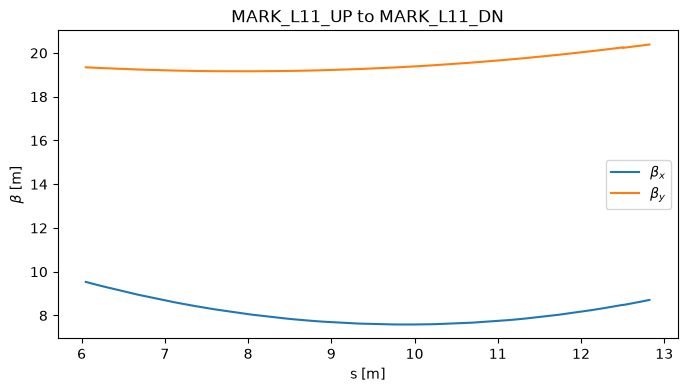

In [5]:
i0, i1 = t.idx("MARK_L11_UP"), t.idx("MARK_L11_DN")
s = t["S"][i0:i1 + 1]

fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(s, t["BETX"][i0:i1 + 1], label=r"$\beta_x$")
ax.plot(s, t["BETY"][i0:i1 + 1], label=r"$\beta_y$")
ax.set_xlabel("s [m]")
ax.set_ylabel(r"$\beta$ [m]")
ax.set_title("MARK_L11_UP to MARK_L11_DN")
ax.legend()
plt.show()

### Optional: as a pandas DataFrame

In [6]:
df = t.to_dataframe()
df.loc["MARK_L11_UP":"MARK_L11_DN", ["S", "BETX", "BETY", "DX"]].head()

,S,BETX,BETY,DX
NAME,,,,
MARK_L11_UP,6.050089,9.534557,19.346458,2.399984
DRIFT_15,6.120902,9.463488,19.332843,2.397299
ORB_ENT_BPM_UP,6.120902,9.463488,19.332843,2.397299
DRIFT_16,6.149311,9.435348,19.327528,2.396221
ORB_ENT_BPM_CT,6.149311,9.435348,19.327528,2.396221


## 2. `device_data.py`: device settings

Devices are a dict of dicts keyed by the full ACNET device name. Each device can hold any keys. The usual ones:
- `kind`: device family: `H`, `V` (dipole correctors), `Q`, `SQ` (quads, skew quads), `SX`, `SS` (sextupoles, skew sextupoles), `VRF` (RF readbacks), `RF` (RF frequency curve), `setting` (GMPS settings).
- `group`, `role`: which physical device it is a part of, and as what (`table`, `scale`, `offset`, `value`); see "Groups" below.
- `table` (table number), `value` (scalar) / `values` (array), `t` / `dt` (time [µs]), `dtoff` (delay [µs]), `unit`.

The file also carries a `meta` dict (created/modified timestamps, notes, source). Long/short sector (`L`/`S`) is only in the name, e.g. `B:QL1T` is the long-sector quad 1 table.

In [7]:
devs, meta = dd.load("data_Booster/10_23_26_BMA.json")
print(len(devs), "devices in", len(dd.groups(devs)), "groups")
print("kinds:", dd.kinds(devs))
meta

578 devices in 289 groups
kinds: ['BFLAT', 'H', 'Q', 'SQ', 'SS', 'SX', 'V']


{'created': '2026-10-23T11:29:02',
 'modified': '2026-10-23T12:43:23',
 'notes': "2026-10-23: B:BFLATS kind 'H' -> 'BFLAT' and B:BFLATT kind 'B:FLAT' -> 'BFLAT' (as in the older BMA files, so kind='H' matches leave B:BFLAT out); group/role keys written (from add_group). Read by ramp_read.py with the new pacsys ramp classes: SQ values and SX/SS dt already match the corrected 10_06_26 file, no /13 or /20 needed. dtoff 156 us on every table incl. B:BFLATT (user). 2026-10-23 (housekeeping, user): key 'table' (ACNET table/slot number) renamed to 'slot' on 578 devices, so it is not confused with role 'table'."}

### Look at a single device

In [8]:
print(devs["B:QL1O"])
{k: v for k, v in devs["B:QL1T"].items() if k not in ("values", "t", "dt")}   # the table, without its arrays

{'value': 4.75677490234375, 'role': 'offset', 'kind': 'Q', 'group': 'B:QL1', 'unit': 'A', 'slot': 1}


{'dtoff': 156.0,
 'role': 'table',
 'kind': 'Q',
 'group': 'B:QL1',
 'unit': 'A',
 'slot': 1}

### Select by kind, role and other keys

In [9]:
sxt = dd.select(devs, kind="SX", role="table")                  # all normal sextupole tables
q_off = dd.select(devs, kind="Q", role="offset")                # all quad offsets
skew_tables = dd.select(devs, kind=["SQ", "SS"], role="table")  # skew quad + skew sextupole tables
bflat = dd.select(devs, group="B:BFLAT")                        # both parts of B:BFLAT
print(len(sxt), len(q_off), len(skew_tables), list(bflat))

sxlt = {n: d for n, d in sxt.items() if n.startswith("B:SXL")}  # long/short sector: from the name
print(len(sxlt), "long-sector sextupole tables")

48 48 96 ['B:BFLATS', 'B:BFLATT']
24 long-sector sextupole tables


### Groups: table, scale factor and offset
The parts of one physical device are separate devices (one per ACNET device) that share a `group` key. `role` says what each part is: `table` (ramp: `values` + `t`), `scale` (scale factor `sf`), `offset` (`value`), or `value` (a stand-alone scalar setting). The code connects parts only through these keys, never by name, so names without a `T`/`S`/`O` suffix (e.g. `B:RF01GA`) work too.

`dd.groups(devs)` gives `{group: {role: device name}}`. The keys are stored in the files. A device without them gets them once on `load`/`add_device` (`dd.add_group`): role from its contents, group = name minus a matching `T`/`S`/`O` suffix, else the name itself. Keys already set are never changed, so irregular names can be grouped by hand (see "Build a device set from scratch").

In [10]:
g = dd.groups(devs)
print("B:QL1:  ", g["B:QL1"])
print("B:BFLAT:", g["B:BFLAT"])
print(devs["B:BFLATS"])

B:QL1:   {'table': 'B:QL1T', 'offset': 'B:QL1O'}
B:BFLAT: {'scale': 'B:BFLATS', 'table': 'B:BFLATT'}
{'sf': -3.0, 'kind': 'BFLAT', 'role': 'scale', 'group': 'B:BFLAT', 'slot': 2}


### Plot a few ramp tables
`t` (µs) is the time of each point and is the only time array used. Raw tables come with `dt` steps; `t = cumsum(dt)` is built once on `load`/`add_device` and `dt` is kept only as a record. `dd.ramp(dev)` returns `(t, values)` with the trailing padding (where `t` stops increasing) removed.

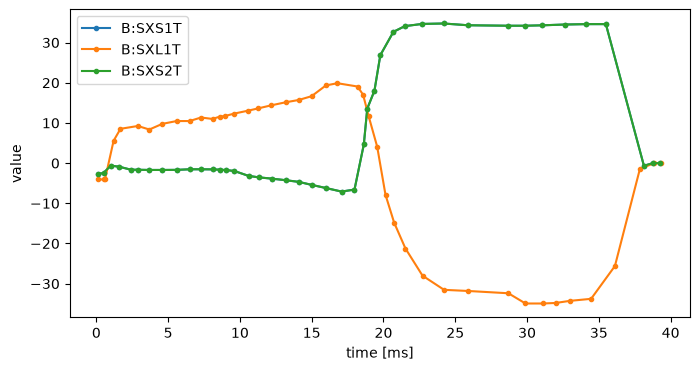

In [11]:
fig, ax = plt.subplots(figsize=(8, 4))
for name in ["B:SXS1T", "B:SXL1T", "B:SXS2T"]:
    t, v = dd.ramp(sxt[name])
    ax.plot(t / 1000, v, ".-", label=name)
ax.set_xlabel("time [ms]")
ax.set_ylabel("value")
ax.legend()
plt.show()

In [12]:
# Stored tables keep all 64 slots; ramp() trims the padding
dev = devs["B:QL1T"]
t, v = dd.ramp(dev)
print(len(dev["dt"]), "slots stored,", len(t), "used; ramp ends at", t[-1], dd.TIME_UNIT)

64 slots stored, 56 used; ramp ends at 38200.0 us


### Working with `t` and `dt`
Give a device either `t` (used as is) or `dt` (`t` is built from it). After that only `t` matters: to shift or edit a ramp, change `dev["t"]` directly. `dt` is not updated.

In [13]:
print("t: ", dev["t"][:5])
print("dt:", dev["dt"][:5], "(source record)")

from_dt = dd.add_device({}, "B:TEST1", values=np.array([0.0, 1.0, 1.0, 0.0]), dt=np.array([1000.0, 1000.0, 3000.0, 1000.0]))
print("t built from dt:", from_dt["t"])
from_t = dd.add_device({}, "B:TEST2", values=np.array([0.0, 1.0]), t=np.array([1000.0, 2000.0]))
print("t given directly:", sorted(from_t))

shifted = dict(dev)
shifted["t"] = dev["t"] + 500.0     # shift a copy by 500 us
print("shifted t:", shifted["t"][:5])

t:  [ 100.  510. 1000. 1600. 1910.]
dt: [100. 410. 490. 600. 310.] (source record)
t built from dt: [1000. 2000. 5000. 6000.]
t given directly: ['group', 'role', 't', 'values']
shifted t: [ 600. 1010. 1500. 2100. 2410.]


### Device values at a time: `value_at` (and raw `sample`)
`dd.value_at(devs, name, t)` gives the value of a device group at `t` [µs] (scalar or array):

value = `S * T(t - dtoff) + O`

with the scale factor `S` = 1 and the offset `O` = 0 when the group has none. `name` is the group (`"B:QL1"`) or any part of it (`"B:QL1T"`); a list of names gives `{name: value}`. `dtoff` [µs] is the table's delay: positive puts the ramp later in the cycle (100 µs for the BMA ramp tables); a readback that should be earlier gets a negative one. When `t - dtoff` is before the first point the first value is held, after the last point the last value.

`dd.sample(dev_or_devs, t)` is the raw lookup of one table at its own time (no `dtoff`, scale or offset); a dict of devices gives `{name: result}`.

In [14]:
print(dd.value_at(devs, "B:QL1", 5000.0))                       # group: table(t - dtoff) + offset
print(dd.value_at(devs, "B:QL1T", [0.0, 5000.0, 1e5]))          # same group, several times
dt0 = devs["B:QL1T"]["dtoff"]
print(dd.sample(devs["B:QL1T"], 5000.0 - dt0) + devs["B:QL1O"]["value"], f"(by hand, dtoff = {dt0:g} us)")

quads = sorted(dd.groups(dd.select(devs, kind="Q")))            # all quad groups
at_20ms = dd.value_at(devs, quads, 20000.0)
list(at_20ms.items())[:4]

1.0625262451171875
[4.7567749  1.06252625 4.7567749 ]
1.0625262451171875 (by hand, dtoff = 156 us)


[('B:QL1', np.float64(-8.946123625102796)),
 ('B:QL10', np.float64(-17.138567472759046)),
 ('B:QL11', np.float64(-13.210955168071546)),
 ('B:QL12', np.float64(-17.031450773540296))]

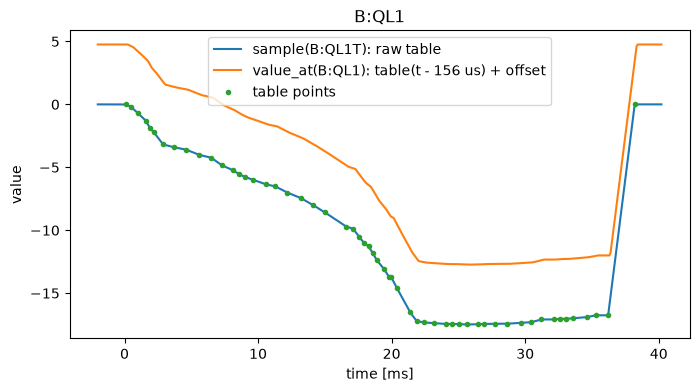

In [15]:
dev = devs["B:QL1T"]
t, v = dd.ramp(dev)
t_fine = np.linspace(-2000, t[-1] + 2000, 500)
fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(t_fine / 1000, dd.sample(dev, t_fine), label="sample(B:QL1T): raw table")
ax.plot(t_fine / 1000, dd.value_at(devs, "B:QL1", t_fine), label=f"value_at(B:QL1): table(t - {dev['dtoff']:g} us) + offset")
ax.plot(t / 1000, v, "o", ms=3, label="table points")
ax.set_xlabel("time [ms]")
ax.set_ylabel("value")
ax.set_title("B:QL1")
ax.legend()
plt.show()

### Bar chart of all quad offsets

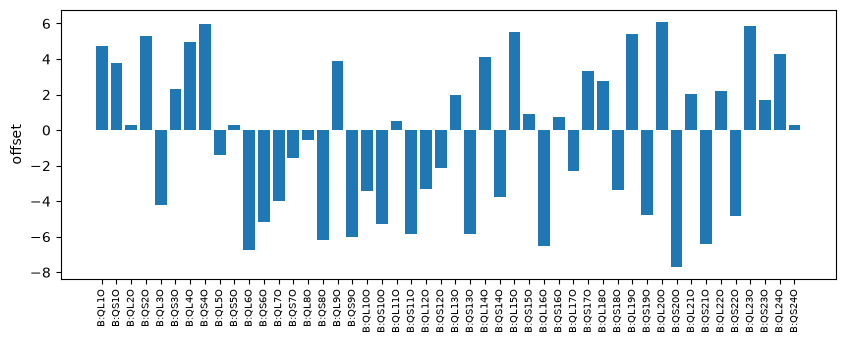

In [16]:
qo = dd.select(devs, kind="Q", role="offset")
fig, ax = plt.subplots(figsize=(10, 3.5))
ax.bar(list(qo), [d["value"] for d in qo.values()])
ax.set_ylabel("offset")
ax.tick_params(axis="x", rotation=90, labelsize=7)
plt.show()

### Add or update devices and save
`add_device` creates a device or merges keys into an existing one. `save` sets `created` (first save) and `modified` in `meta`.

In [17]:
dd.add_device(devs, "B:QL1O", unit="A")   # merges a new key into the existing device (in memory)
devs["B:QL1O"]

{'value': 4.75677490234375,
 'role': 'offset',
 'kind': 'Q',
 'group': 'B:QL1',
 'unit': 'A',
 'slot': 1}

In [18]:
meta["notes"] = meta.get("notes", "") + " Added units to B:QL1O."
# dd.save(devs, "data_Booster/10_23_26_BMA.json", meta)   # uncomment to write

### Build a device set from scratch (no JSON)
Start from an empty dict and call `add_device` for each device. The input can be in any form you have: a dict of dicts, parallel lists, arrays from another script, etc. Each device gets `group`/`role` from its contents and name unless they are given.

The new set is saved to its own file, separate from the BMA file.

In [19]:
new = {}

# From a dict of dicts
positions = {
    "B:HST01L": {"values": [1.0, 2.0, 3.0], "unit": "mm"},
    "B:HST02L": {"values": [4.0, 5.0, 6.0], "unit": "mm"},
}
for name, fields in positions.items():
    dd.add_device(new, name, kind="position", **fields)     # no time array: role "value"

# From parallel lists, e.g. names and readings from another source
names = ["B:QL1O", "B:QL2O", "B:QL3O"]
offsets = [0.5, -0.25, 1.0]
for name, val in zip(names, offsets):
    dd.add_device(new, name, kind="Q", table=2, value=val, unit="A")   # role "offset", group "B:QL1", ...

# Array settings: numpy arrays can go in directly
dd.add_device(new, "B:SXL1T", kind="SX", table=2, dtoff=100.0,
              values=np.linspace(0, 30, 5), dt=np.full(5, 1000.0))      # role "table", group "B:SXL1"

# A part whose name does not follow the T/S/O pattern: give group and role by hand
dd.add_device(new, "B:SXL1SF", kind="SX", sf=0.5, group="B:SXL1", role="scale")

new

{'B:HST01L': {'kind': 'position',
  'values': [1.0, 2.0, 3.0],
  'unit': 'mm',
  'role': 'value',
  'group': 'B:HST01L'},
 'B:HST02L': {'kind': 'position',
  'values': [4.0, 5.0, 6.0],
  'unit': 'mm',
  'role': 'value',
  'group': 'B:HST02L'},
 'B:QL1O': {'kind': 'Q',
  'table': 2,
  'value': 0.5,
  'unit': 'A',
  'role': 'offset',
  'group': 'B:QL1'},
 'B:QL2O': {'kind': 'Q',
  'table': 2,
  'value': -0.25,
  'unit': 'A',
  'role': 'offset',
  'group': 'B:QL2'},
 'B:QL3O': {'kind': 'Q',
  'table': 2,
  'value': 1.0,
  'unit': 'A',
  'role': 'offset',
  'group': 'B:QL3'},
 'B:SXL1T': {'kind': 'SX',
  'table': 2,
  'dtoff': 100.0,
  'values': array([ 0. ,  7.5, 15. , 22.5, 30. ]),
  'dt': array([1000., 1000., 1000., 1000., 1000.]),
  't': array([1000., 2000., 3000., 4000., 5000.]),
  'role': 'table',
  'group': 'B:SXL1'},
 'B:SXL1SF': {'kind': 'SX', 'sf': 0.5, 'group': 'B:SXL1', 'role': 'scale'}}

### Select, merge and save the new set

In [20]:
print(dd.kinds(new))
print(list(dd.select(new, kind="position")))
print("groups:", dd.groups(new))
print("B:SXL1 at 2600 us = 0.5 * table(2500 us):", dd.value_at(new, "B:SXL1", 2600.0))

# Merge into another set (entries in `new` replace whole devices with the same name)
combined = {**devs, **new}
print(len(devs), "+", len(new), "->", len(combined), "devices")

import tempfile
from pathlib import Path
new_meta = {"source": "examples.ipynb", "notes": "hand-entered example devices"}
example_file = Path(tempfile.mkdtemp()) / "example_devices.json"   # scratch folder, not data_Booster/
dd.save(new, example_file, new_meta)
dd.load(example_file)[1]

['Q', 'SX', 'position']
['B:HST01L', 'B:HST02L']
groups: {'B:HST01L': {'value': 'B:HST01L'}, 'B:HST02L': {'value': 'B:HST02L'}, 'B:QL1': {'offset': 'B:QL1O'}, 'B:QL2': {'offset': 'B:QL2O'}, 'B:QL3': {'offset': 'B:QL3O'}, 'B:SXL1': {'table': 'B:SXL1T', 'scale': 'B:SXL1SF'}}
B:SXL1 at 2600 us = 0.5 * table(2500 us): 5.625
578 + 7 -> 581 devices


{'source': 'examples.ipynb',
 'notes': 'hand-entered example devices',
 'created': '2026-10-25T20:51:43',
 'modified': '2026-10-25T20:51:43'}

## 3. `curve_csv.py`: RF frequency curve

`read_curve(path, t_start=1875.0)` reads an ACNET curve CSV (times in ms) and returns `(name, device)`. The device has `values` + `t` (µs, no `dt`), like a ramp table, so `dd.ramp`, `dd.sample` and `dd.value_at` work on it. `t_start` is the time [µs] of the curve's first point. `set_start(dev, t)` moves an already loaded curve.

The RF frequency curve used here was read that way and saved as `data_Booster/rf_freq_20260914.json` (the source CSV is available from the author); below it is loaded from the JSON.

In [21]:
rf_devs, rf_meta = dd.load("data_Booster/rf_freq_20260914.json")
name = "tblFreqCurveFF"
rf = rf_devs[name]
print(name, rf["unit"], "t_start =", rf["t_start"], "us, dtoff =", rf["dtoff"], "us")
print("f at 20 ms:", dd.sample(rf, 20000.0), rf["unit"])

tblFreqCurveFF MHz t_start = 1875.0 us, dtoff = 155.2 us
f at 20 ms: 52.310312333333336 MHz


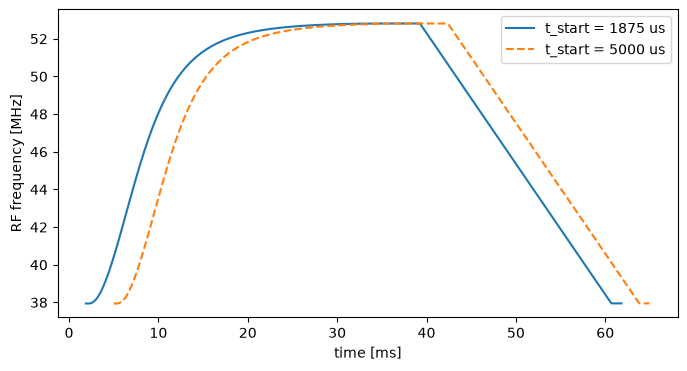

In [22]:
fig, ax = plt.subplots(figsize=(8, 4))
t, f = dd.ramp(rf)
ax.plot(t / 1000, f, label="t_start = 1875 us")
t, f = dd.ramp(set_start(dict(rf), 5000.0))     # shifted copy, rf unchanged
ax.plot(t / 1000, f, "--", label="t_start = 5000 us")
ax.set_xlabel("time [ms]")
ax.set_ylabel("RF frequency [MHz]")
ax.legend()
plt.show()

### Load the saved RF device
`data_Booster/rf_freq_20260914.json` holds this curve (`t_start` = 1875 µs, the programmed delay; `dtoff` = 155.2 µs, the extra delay fitted by `timing_fit.py`). It is its own group (`tblFreqCurveFF`, role `table`) and can be merged with the magnet devices.

In [23]:
rf_devs, rf_meta = dd.load("data_Booster/rf_freq_20260914.json")
# dd.save(rf_devs, "data_Booster/rf_freq_20260914.json", rf_meta)   # after set_start(...), to write
everything = {**devs, **rf_devs}
dd.value_at(everything, "tblFreqCurveFF", 20000.0)

np.float64(52.29335725)

### RF station voltage readbacks
`data_Booster/10_23_26_VRF_READBACK_clean.json`: `B:RF01GA` … `B:RF22GA` (kind `VRF`, kV/T, every 1 ms from t = 0, `dtoff` = 0 as read; the old file had 2050 µs, the RF phase curves are at 1875 µs, and the readback offset is still to be checked). Each is a table without a `T` in its name, so it is its own group. Cleaned copy of the raw `10_23_26_VRF_READBACK.json` (same steps as on 2026-10-06, see `ISSUES.md`):
- t = 0 … 49 ms (the raw file has 49 times for 50 values); the junk sample at 41 ms is set to 0.
- RF21 and RF22 have no data (`values` None): `value_at` / `sample` give 0.
- RF02, RF03 and RF11 look off (flat ~1.7 kV/T).
- RF01 was divided by 20 (it reads ~20x the other stations; factor inferred, not confirmed).

{'table': 'B:RF01GA'}
at 10 ms: {'B:RF01GA': 50.44, 'B:RF04GA': 52.11, 'B:RF21GA': 0.0}


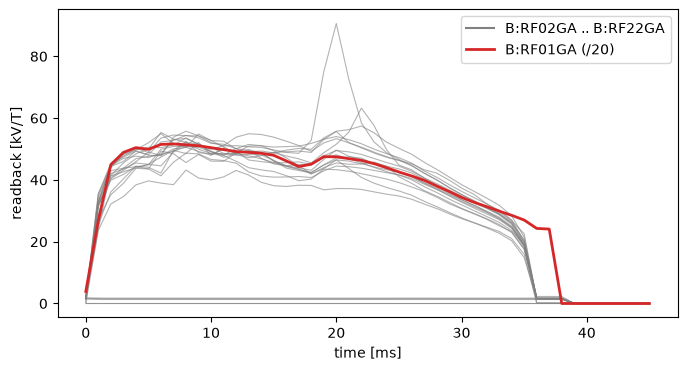

In [24]:
vrf, vrf_meta = dd.load("data_Booster/10_23_26_VRF_READBACK_clean.json")
print(dd.groups(vrf)["B:RF01GA"])
at_10ms = dd.value_at(vrf, ["B:RF01GA", "B:RF04GA", "B:RF21GA"], 10000.0)
print("at 10 ms:", {n: round(float(v), 2) for n, v in at_10ms.items()})

t = np.linspace(0, 45000, 451)
fig, ax = plt.subplots(figsize=(8, 4))
for name in sorted(vrf):
    if name != "B:RF01GA":
        ax.plot(t / 1000, dd.value_at(vrf, name, t), color="gray", lw=0.8, alpha=0.6)
ax.plot([], [], color="gray", label="B:RF02GA .. B:RF22GA")
ax.plot(t / 1000, dd.value_at(vrf, "B:RF01GA", t), color="C3", lw=2, label="B:RF01GA (/20)")
ax.set_xlabel("time [ms]")
ax.set_ylabel("readback [kV/T]")
ax.legend()
plt.show()

### RF phase curves
`data_Booster/rf_phase_curves.json` holds the two RF phase curves (kind `RFPH`, degrees, `t` in µs):
- group `RFA` = table `RFA` (the phase program's RFA) + offset `RFAO` (0°)
- group `RFB` = table `RFB` (the phase program's RFB − 180°) + offset `RFBO` (0°)

Both tables start at the programmed 1875 µs (`t_start`) and have `dtoff` = 155.2 µs, the extra delay fitted by `timing_fit.py`. MEV400 flat injection runs 1986–2556 µs (BDOT 2271 ± TFLAT 285). The 17.43 ms phase jump lands at 19.47 ms, 0.15 ms before transition in the model (19.61 ms). `dd.value_at(phases, "RFA", t)` = RFA(t − dtoff) + RFAO. Outside the table each curve holds its first / last value. After 0.3 ms, RFB is 4° above RFA.

Device `RF_CAVITY_PHASE` (role `map`) says which curve each cavity follows: phase A (`RFA`) = cavities 2, 3, 6, 7, 9, 12, 13, 16, 17, 20, 22; phase B (`RFB`) = the other 11. `madx_input` uses it automatically when it is in the device pool (`madx_input.phase_names(devs)`). Its `off` list (21, 22: zero on the readbacks) sets those cavities' voltage to 0.

{'RFA': {'table': 'RFA', 'offset': 'RFAO'}, 'RFB': {'table': 'RFB', 'offset': 'RFBO'}, 'RF_CAVITY_PHASE': {'map': 'RF_CAVITY_PHASE'}}
{'RFA': {'role': 'table', 'unit': 'deg', 'dtoff': 155.2}, 'RFAO': {'role': 'offset', 'unit': 'deg', 'value': 0.0}, 'RFB': {'role': 'table', 'unit': 'deg', 'dtoff': 155.2}, 'RFBO': {'role': 'offset', 'unit': 'deg', 'value': 0.0}, 'RF_CAVITY_PHASE': {'role': 'map'}}
at 10 ms: {'RFA': np.float64(3.92186600000001), 'RFB': np.float64(7.921965999999999)}
phase A: ['2', '3', '6', '7', '9', '12', '13', '16', '17', '20', '22']  phase B: ['1', '4', '5', '8', '10', '11', '14', '15', '18', '19', '21']


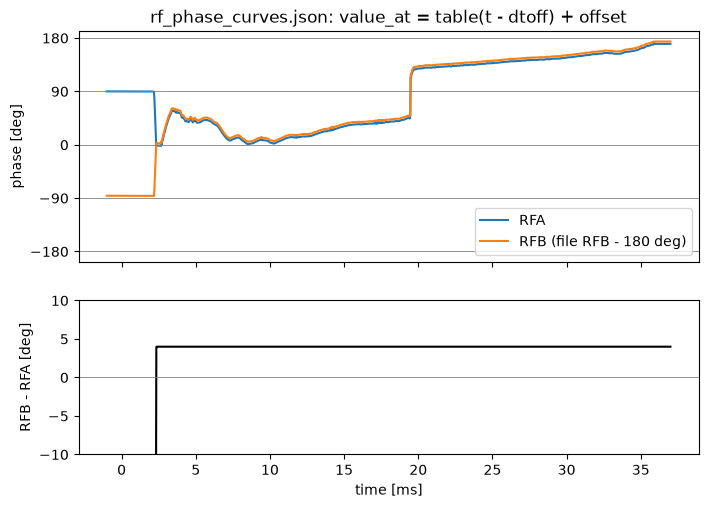

In [25]:
phases, phase_meta = dd.load("data_Booster/rf_phase_curves.json")
print(dd.groups(phases))
print({n: {k: d[k] for k in ("role", "unit", "dtoff", "value") if k in d} for n, d in phases.items()})
print("at 10 ms:", dd.value_at(phases, ["RFA", "RFB"], 10000.0))
cav = phases["RF_CAVITY_PHASE"]["cavities"]
print("phase A:", [n for n, g in cav.items() if g == "RFA"], " phase B:", [n for n, g in cav.items() if g == "RFB"])

t = np.arange(-1000, 37001, 5.0)          # us
v = dd.value_at(phases, ["RFA", "RFB"], t)
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(8, 5.5), sharex=True, gridspec_kw={"height_ratios": [3, 2]})
ax1.plot(t / 1000, v["RFA"], label="RFA")
ax1.plot(t / 1000, v["RFB"], label="RFB (file RFB - 180 deg)")
for y in (-180, -90, 0, 90, 180):
    ax1.axhline(y, color="gray", lw=0.6)
ax1.set_yticks([-180, -90, 0, 90, 180])
ax1.set_ylabel("phase [deg]")
ax1.legend(loc="lower right")
ax2.plot(t / 1000, v["RFB"] - v["RFA"], color="k")
ax2.axhline(0, color="gray", lw=0.6)
ax2.set_ylim(-10, 10)
ax2.set_ylabel("RFB - RFA [deg]")
ax2.set_xlabel("time [ms]")
ax1.set_title("rf_phase_curves.json: value_at = table(t - dtoff) + offset")
plt.show()

## 4. `ramp_timing.py`: energy conversions

Kinetic energy (KE, GeV) is the primary quantity. For a proton (`rt.MASS` = 0.938272 GeV), each quantity has `ke_to_X` / `X_to_ke`:

| name | quantity | unit |
|---|---|---|
| `beta`, `gamma` | relativistic β, γ | |
| `pc` | momentum × c | GeV |
| `brho` | rigidity p/q | T m |
| `frev` | revolution frequency β c / C | MHz |
| `frf` | RF frequency, `rt.HARMONIC` (84) × frev | MHz |

`frev`/`frf` take `circumference=` (default `rt.CIRCUMFERENCE` = 474.2 m). `rt.convert(value, from, to)` converts any pair through KE. Scalars, lists and arrays all work.

In [26]:
ke = [0.4, 0.8, 8.0]     # GeV
for q in rt.QUANTITIES:
    print(f"{q:6s}", rt.convert(ke, "ke", q))

ke     [0.4 0.8 8. ]
beta   [0.71305596 0.84181071 0.99447513]
gamma  [1.42631557 1.85263114 9.5263114 ]
pc     [0.95426289 1.46329605 8.88888932]
brho   [ 3.18307839  4.88103024 29.65014325]
frev   [0.45079882 0.53219844 0.62871393]
frf    [37.86710082 44.70466905 52.81196993]


In [27]:
print(rt.ke_to_frf(0.4), "MHz at KE = 0.4 GeV")
print(rt.frf_to_ke([37.942699, 52.811501]), "GeV from the RF curve's first and peak frequency")
print(rt.convert(3.0, "brho", "pc"), "GeV pc at 3 T m")
print(rt.ke_to_frev(0.4, circumference=474.0), "MHz frev on a 474.0 m orbit")

37.86710082226594 MHz at KE = 0.4 GeV
[0.40277495 7.99288544] GeV from the RF curve's first and peak frequency
0.899377374 GeV pc at 3 T m
0.4509890297849735 MHz frev on a 474.0 m orbit


### KE along the RF frequency curve
Converting the RF curve (section 3) gives KE vs time.

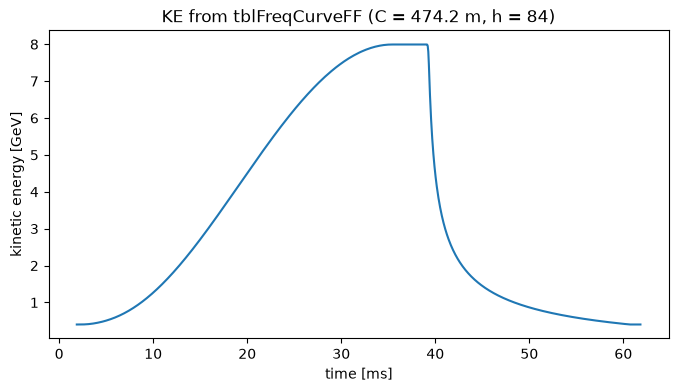

In [28]:
t, f = dd.ramp(rf)
fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(t / 1000, rt.frf_to_ke(f))
ax.set_xlabel("time [ms]")
ax.set_ylabel("kinetic energy [GeV]")
ax.set_title("KE from tblFreqCurveFF (C = 474.2 m, h = 84)")
plt.show()

### GMPS ramp (plain sine)
All ramp functions take and return KE [GeV] vs time [µs]. The GMPS sine is in field, so it is a sine in pc; the KE ↔ pc conversion happens inside each function.

`rt.ramp_gmps(t, vimin, vimax, freq_pulse=15.0, t_offset=0.0)` gives `vimin` at `t = t_offset` and `vimax` half a period later, repeating every `1e6 / freq_pulse` µs (`freq_pulse` in Hz).

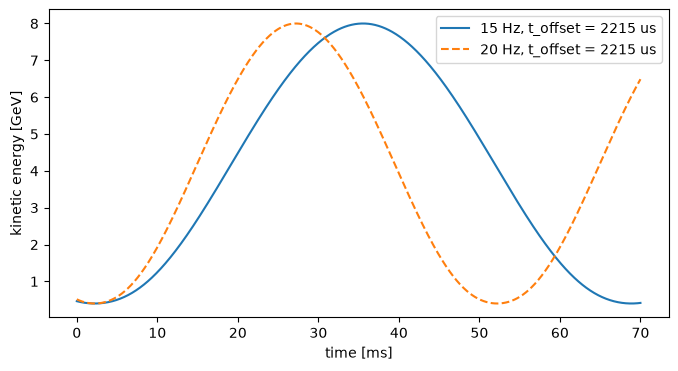

In [29]:
t = np.linspace(0, 70000, 1000)     # us
fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(t / 1000, rt.ramp_gmps(t, vimin=0.4, vimax=8.0, freq_pulse=15.0, t_offset=2215.0), label="15 Hz, t_offset = 2215 us")
ax.plot(t / 1000, rt.ramp_gmps(t, vimin=0.4, vimax=8.0, freq_pulse=20.0, t_offset=2215.0), "--", label="20 Hz, t_offset = 2215 us")
ax.set_xlabel("time [ms]")
ax.set_ylabel("kinetic energy [GeV]")
ax.legend()
plt.show()

### Inverse: time for a KE
`rt.time_gmps(ke, vimin, vimax, freq_pulse, t_offset)` inverts `ramp_gmps` on the rising half: `vimin` → `t_offset`, `vimax` → half a period later. KE outside `[vimin, vimax]` gives `nan`.

In [30]:
ke = [0.4, 1.0, 4.2, 8.0]
t_ke = rt.time_gmps(ke, vimin=0.4, vimax=8.0, freq_pulse=15.0, t_offset=2215.0)
print("t [us]:", t_ke)
print("round trip:", rt.ramp_gmps(t_ke, 0.4, 8.0, 15.0, 2215.0))
print("out of range:", rt.time_gmps([0.3, 9.0], 0.4, 8.0))

t [us]: [ 2215.          8808.91137251 19230.21732262 35548.33333333]
round trip: [0.4 1.  4.2 8. ]
out of range: [nan nan]


### Flat injection
`rt.vimin_flat(viflat, vimax, t_flat, freq_pulse)` returns the `vimin` for which `ramp_gmps` (minimum at `t_offset`) reaches `viflat` at `t = t_offset + t_flat`. `t_flat` is in µs and must be shorter than half a period.

`rt.ramp_flat(t, viflat, vimax, t_flat, freq_pulse, t_offset)` is one flat-injection pulse: `viflat` on `(t_offset - t_flat, t_offset + t_flat)`, the GMPS sine with that `vimin` out to the peaks at `t_offset ± half a period`, and `vimax` beyond them. There is no separate inverse: above `viflat`, `time_gmps` with `vimin_flat(...)` gives the time.

vimin = 0.29057606142864834
check: ramp_gmps at t_offset + t_flat = 0.4000000000000006


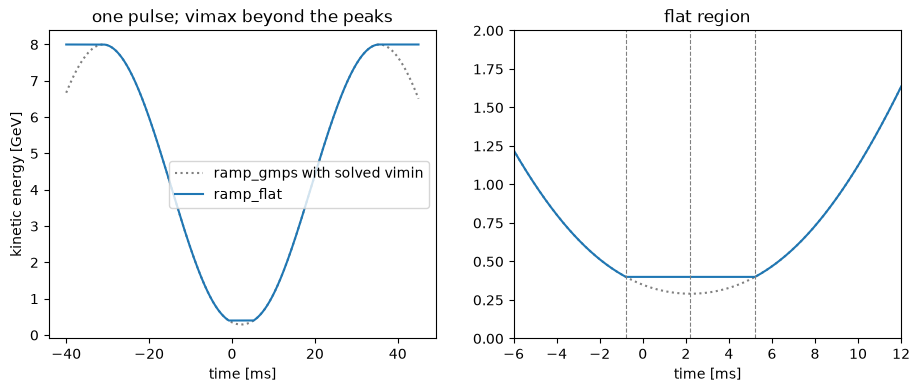

In [31]:
t_offset, t_flat, viflat, vimax, f = 2215.0, 3000.0, 0.4, 8.0, 15.0   # t_flat exaggerated to show the shape
vimin = rt.vimin_flat(viflat, vimax, t_flat, freq_pulse=f)
print("vimin =", vimin)
print("check: ramp_gmps at t_offset + t_flat =", rt.ramp_gmps(t_offset + t_flat, vimin, vimax, f, t_offset))

t = np.linspace(-40000, 45000, 3000)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4))
for ax in (ax1, ax2):
    ax.plot(t / 1000, rt.ramp_gmps(t, vimin, vimax, f, t_offset), ":", color="gray", label="ramp_gmps with solved vimin")
    ax.plot(t / 1000, rt.ramp_flat(t, viflat, vimax, t_flat, f, t_offset), label="ramp_flat")
    ax.set_xlabel("time [ms]")
ax1.set_ylabel("kinetic energy [GeV]")
ax1.set_title("one pulse; vimax beyond the peaks")
ax1.legend()
for x in (t_offset - t_flat, t_offset, t_offset + t_flat):
    ax2.axvline(x / 1000, color="gray", ls="--", lw=0.8)
ax2.set_xlim(-6, 12)
ax2.set_ylim(0, 2.0)
ax2.set_title("flat region")
plt.show()

### Ramp settings files and KE vs time
`data_Booster/10_23_26_MISC_MEV400.json` and `data_Booster/10_23_26_MISC_PIP_II.json` hold the GMPS settings as role `setting` devices (each its own group; `rt.RAMP_DEVICES`): `B:VIMIN`, `B:VIMAX` (GMPS currents, A), `GMPSFRQ` (Hz), `TFLAT` (µs), `BDOT` (time of the sine minimum, µs), `CIRC` (circumference from the MAD-X twiss `LENGTH`, m) and `KEMAX` (extraction KE, GeV). They also hold the extraction kickers `B:BEX2T` (ramp) and `MKSON` (section 5).

Only the ratio of the two currents is known, so the energy needs one anchor: `B:VIMAX` is the current at the extraction energy `KEMAX`, and the field (pc) is proportional to the current. Then `vimax = KEMAX` and `viflat = pc_to_ke(pc(KEMAX) · VIMIN / VIMAX)` (`B:VIMIN` is the flat injection level): 0.397 GeV for MEV400 and 0.795 GeV for PIP-II with these files (`KEMAX` = 8.05 GeV), instead of the nominal 0.4 / 0.8 GeV.

`rt.ramp_settings(devs)` returns them as `viflat`, `vimax`, `t_flat`, `freq_pulse`, `t_offset`, `circumference`, plus `amps_per_pc` (A per GeV of pc) and `ke_max`.

MEV400 {'t_flat': 285.0, 'freq_pulse': 15.0, 't_offset': 2271.0, 'viflat': 0.3932466500545364, 'vimax': 7.988, 'vimin': 0.392231746995104, 'amps_per_pc': 108.94690624845605, 'ke_max': 7.988, 'circumference': 474.200000001}
PIP_II {'t_flat': 400.0, 'freq_pulse': 20.0, 't_offset': 2271.0, 'viflat': 0.7904426040149379, 'vimax': 7.988, 'vimin': 0.786503768365282, 'amps_per_pc': 108.94690624845605, 'ke_max': 7.988, 'circumference': 474.2002212361}


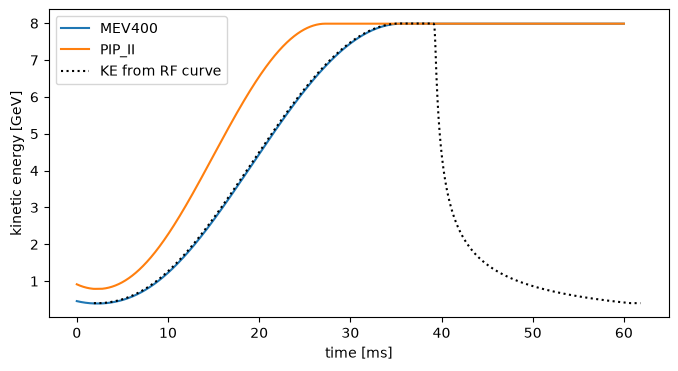

In [32]:
fig, ax = plt.subplots(figsize=(8, 4))
t = np.linspace(0, 60000, 3000)
for f in ["MEV400", "PIP_II"]:
    s = rt.ramp_settings(dd.load(f"data_Booster/10_23_26_MISC_{f}.json")[0])
    print(f, s)
    ax.plot(t / 1000, rt.ramp_flat(t, s["viflat"], s["vimax"], s["t_flat"], s["freq_pulse"], s["t_offset"]), label=f)
t_rf, f_rf = dd.ramp(rf)
ax.plot(t_rf / 1000, rt.frf_to_ke(f_rf), ":", color="k", label="KE from RF curve")
ax.set_xlabel("time [ms]")
ax.set_ylabel("kinetic energy [GeV]")
ax.legend()
plt.show()

In [33]:
s = rt.ramp_settings(dd.load("data_Booster/10_23_26_MISC_MEV400.json")[0])
args = (s["viflat"], s["vimax"], s["t_flat"], s["freq_pulse"], s["t_offset"])
t_inj = s["t_offset"] - s["t_flat"]                      # beam injection: 2007 us
print(rt.ramp_flat([t_inj, 5000.0, 20000.0, 50000.0], *args), f"GeV at {t_inj / 1000:g} (injection), 5, 20, 50 ms")

# expected RF frequency along the ramp, using the lattice circumference
print(rt.ke_to_frf(rt.ramp_flat([t_inj, 20000.0], *args), s["circumference"]), f"MHz at {t_inj / 1000:g}, 20 ms")

sel = (t_rf > 2500) & (t_rf < 35000)
diff = rt.ramp_flat(t_rf[sel], *args) - rt.frf_to_ke(f_rf[sel], s["circumference"])
print(f"MEV400 model - RF curve: rms {diff.std() * 1000:.1f} MeV, max {abs(diff).max() * 1000:.1f} MeV")

[0.39324665 0.48771804 4.45061621 7.988     ] GeV at 1.986 (injection), 5, 20, 50 ms
[37.68049426 52.29422754] MHz at 1.986, 20 ms
MEV400 model - RF curve: rms 14.2 MeV, max 54.6 MeV


### Turns along the ramp
`t_n[n]` is the time [µs] of turn `n`, found by integrating the revolution frequency from injection (`t_start`) to the top of the ramp, followed by `n_after` (default 100) turns held at the top (flattop) frequency.
- `rt.turns_flat(viflat, vimax, t_flat, freq_pulse, t_offset, circumference, t_start=None, n_after=100)`: default `t_start = t_offset - t_flat` (start of flat injection); top = `vimax`.
- `rt.turns_gmps(vimin, vimax, freq_pulse, t_offset, circumference, t_start=None, n_after=100)`: default `t_start = t_offset`; top = `vimax`.
- `rt.turns_device(dev, t_start=None, n_after=100, harmonic=84)`: frev = `values / harmonic` from a frequency device (e.g. the RF curve), linearly interpolated; default `t_start` = first point; top = highest frequency.

MEV400: turns 0..19947, 1986.0 -> 35762.3 us
PIP_II: turns 0..15454, 1871.0 -> 27429.0 us
RF curve (tblFreqCurveFF): turns 0..19845, 2030.2 -> 35609.0 us


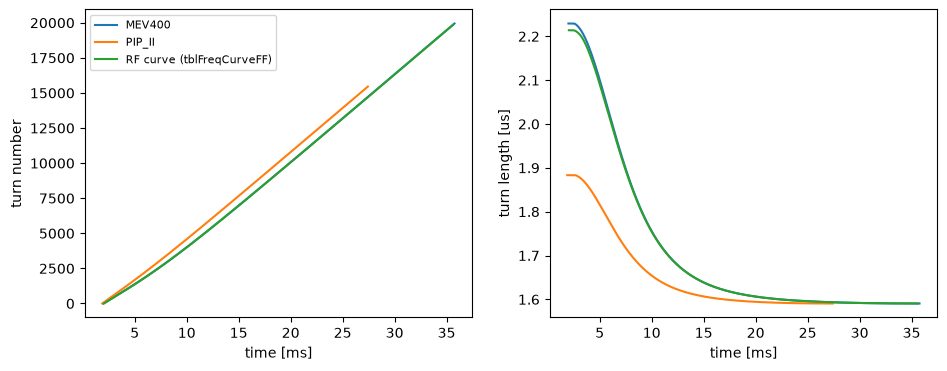

In [34]:
runs = {}
for f in ["MEV400", "PIP_II"]:
    s = rt.ramp_settings(dd.load(f"data_Booster/10_23_26_MISC_{f}.json")[0])
    runs[f] = rt.turns_flat(s["viflat"], s["vimax"], s["t_flat"], s["freq_pulse"], s["t_offset"], s["circumference"])
runs["RF curve (tblFreqCurveFF)"] = rt.turns_device(rf)

for name, t_n in runs.items():
    print(f"{name}: turns 0..{len(t_n) - 1}, {t_n[0]:.1f} -> {t_n[-1]:.1f} us")

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4))
for name, t_n in runs.items():
    ax1.plot(t_n / 1000, np.arange(len(t_n)), label=name)
    ax2.plot(t_n[1:] / 1000, np.diff(t_n), label=name)
ax1.set_xlabel("time [ms]")
ax1.set_ylabel("turn number")
ax2.set_xlabel("time [ms]")
ax2.set_ylabel("turn length [us]")
ax1.legend(fontsize=8)
plt.show()

In [35]:
# KE at every turn, and the turn number at a given time
s = rt.ramp_settings(dd.load("data_Booster/10_23_26_MISC_MEV400.json")[0])
args = (s["viflat"], s["vimax"], s["t_flat"], s["freq_pulse"], s["t_offset"])
t_n = runs["MEV400"]
ke_n = rt.ramp_flat(t_n, *args)
print("KE at turns 0, 1000, 10000:", ke_n[[0, 1000, 10000]])
print("turn number at 5 ms and 20 ms:", np.searchsorted(t_n, [5000.0, 20000.0]) - 1)
t_top = s["t_offset"] + 0.5e6 / s["freq_pulse"]
n_top = np.searchsorted(t_n, t_top)
print(f"top of ramp at {t_top:.1f} us, turn {n_top}; {len(t_n) - n_top} flattop turns of {t_n[-1] - t_n[-2]:.4f} us")
print("with n_after=10:", len(rt.turns_flat(*args, s["circumference"], n_after=10)) - n_top, "flattop turns")

KE at turns 0, 1000, 10000: [0.39324665 0.4391198  4.41392158]
turn number at 5 ms and 20 ms: [ 1377 10062]
top of ramp at 35604.3 us, turn 19848; 100 flattop turns of 1.5906 us
with n_after=10: 10 flattop turns


### Energy gain per turn
`t_n, ke_n, dke_n = rt.turn_energy(source, t_start=None, n_after=100)` works with either source:
- a settings dict from `rt.ramp_settings(...)`: `turns_flat` + `ramp_flat`, using the settings' circumference;
- a frequency device (e.g. the RF curve): `turns_device`, with KE from the frequency (held at its top on the flattop turns); `circumference=` defaults to 474.2 m.

`dke_n[n] = ke_n[n + 1] - ke_n[n]` is the KE [GeV] gained on turn `n`.

MEV400: 19948 turns, KE 0.3932 -> 7.9880 GeV, max gain 0.591 MeV/turn at turn 9401
PIP_II: 15455 turns, KE 0.7904 -> 7.9880 GeV, max gain 0.738 MeV/turn at turn 7518
RF curve (tblFreqCurveFF): 19846 turns, KE 0.4028 -> 7.9929 GeV, max gain 0.596 MeV/turn at turn 9626


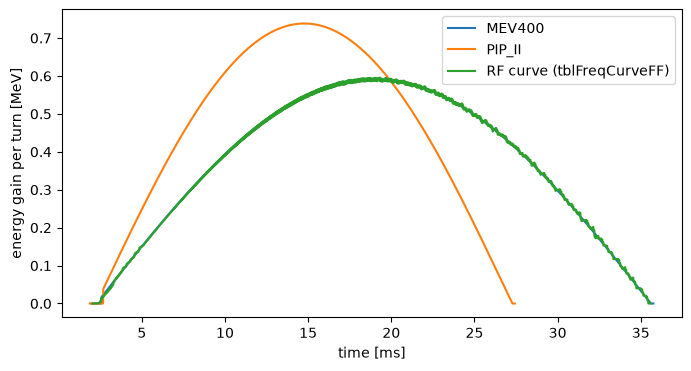

In [36]:
sources = {
    "MEV400": rt.ramp_settings(dd.load("data_Booster/10_23_26_MISC_MEV400.json")[0]),
    "PIP_II": rt.ramp_settings(dd.load("data_Booster/10_23_26_MISC_PIP_II.json")[0]),
    "RF curve (tblFreqCurveFF)": rf,
}
fig, ax = plt.subplots(figsize=(8, 4))
for name, src in sources.items():
    t_n, ke_n, dke_n = rt.turn_energy(src)
    print(f"{name}: {len(t_n)} turns, KE {ke_n[0]:.4f} -> {ke_n[-1]:.4f} GeV, "
          f"max gain {dke_n.max() * 1e3:.3f} MeV/turn at turn {np.argmax(dke_n)}")
    ax.plot(t_n[:-1] / 1000, dke_n * 1e3, label=name)
ax.set_xlabel("time [ms]")
ax.set_ylabel("energy gain per turn [MeV]")
ax.legend()
plt.show()

## 5. `madx_input.py`: the MAD-X input file

`vals = common_values(t, devs, settings, ke_source=None, rf="auto")` works out everything that goes into the common input, and `write_common(path, vals)` writes it (layout of the user's original `Common_Booster_Input.dat` template, plus new scalars). `vals["KE_true"]`, `vals["I_QL1"]`, `vals["V01"]` give any value; `vals.scalars` / `vals.currents` are the dicts. `devs` is one pool with everything used (BMA tables and offsets, and any RF devices):
- `KE_true` [GeV]: beam KE at `t`, from `ramp_flat` (settings), or from `ke_source` (a frequency device, e.g. the RF curve) if given.
- `KE` [GeV]: effective KE of the GMPS alone, `rt.ke_gmps_at(settings, t)` (plain sine with the `vimin_flat` minimum). It sets Brho and the magnet strengths in the lattices. It dips below `KE_true` in the flat region; `B:BFLAT` makes up the difference. (Format of 2026-10-12: before, `KE` was the beam and `KE_GMPS` the GMPS.)
- `FREQ_RF` [MHz]: the equivalent RF frequency of `ramp_flat`, `rt.ke_to_frf(rt.ke_at(settings, t), B:CIRC)`, for all 22 cavities. Always from the settings, also when `KE_true` comes from `ke_source`.
- `V01`..`V22` (voltage [MV]) and `LAG01`..`LAG22` (lag [2π]) for cavities `RF01`..`RF22` (`VOLT=V<nn>, LAG=LAG<nn>, FREQ=FREQ_RF` in the lattices), from the RF mode (below). With no RF devices, all 0.
- `I_<family><L|S><n>` (288 values): `dd.value_at(devs, "B:<family><L|S><n>", t)` = ramp table at `t - dtoff` (BMA: 156 µs in the 10_23_26 file) + offset. `I_HS<n>` and `I_HL<n>` also get group `B:BFLAT`: `sf` (`B:BFLATS`) × `B:BFLATT(t - dtoff)`. Without a `B:BFLATT` the header says nothing was added. A current whose device is not in `devs` at all is written as 0 and listed in the header (`missing_devices(devs)`).
- `I_BEX2` [A] and `MKS_ON` (extraction kickers, `mxin.KICKERS`): `dd.value_at(devs, "B:BEX2", t)` (the `B:BEX2T` ramp; BEX2..BEX4 in the lattices) and `dd.value_at(devs, "MKSON", t)` (one setting, normally 0; the lattices kick `0.005 · MKS_ON · Brho_EXT / Brho`; set it with an override, e.g. `{"MKSON": 1.0}` in section 6). Both come from the MISC files. Like the currents, 0 and listed in the header if not in `devs`.
- Outside a ramp each table holds its first / last value, at any `t` (also `t < 0`). For `t < 0`, `KE_true = KE = viflat`.

 `rf="off"` writes no RF whatever RF devices are in `devs`.

The lattice files `call` `Common_Booster_input.dat` from the folder MAD-X runs in (`run_madx`, section 6, writes it in `madx_files/`). The examples here write it to a temporary folder, so `madx_files/` is not touched. An existing file is only replaced if a `madx_input` writer made it (else `overwrite=True`). `/mnt/c` is case-insensitive: two names that differ only in case are the same file.

In [37]:
from pathlib import Path

bma, _ = dd.load("data_Booster/10_23_26_BMA.json")
misc, _ = dd.load("data_Booster/10_23_26_MISC_MEV400.json")   # GMPS settings, B:BEX2T, MKSON
bma = {**bma, **misc}
settings = rt.ramp_settings(misc)

import tempfile
input_file = Path(tempfile.mkdtemp()) / "Common_Booster_input.dat"   # scratch copy, not madx_files/

path = write_common(input_file, common_values(5000.0, bma, settings))
print(path)
print("".join(open(path).readlines()[:20]))

/tmp/tmpx5gcm4t_/Common_Booster_input.dat
!Beam energy and magnet current inputs
!Generated 2026-10-25T20:51:44 by madx_input.write_common
!t = 5000.0 us
!KE_true (beam) from ramp_flat settings; KE (GMPS) from the plain GMPS sine
!GMPS: B:VIMAX = 967.1023559570312 A at KEMAX = 7.988 GeV, 108.94690624845605 A per GeV of pc; B:VIMIN -> trough 0.392231746995104 GeV, flat 0.3932466500545364 GeV
!I_ = S * T(t - dtoff) + O (scale factor, ramp table, offset); I_HS, I_HL also + sf (B:BFLATS) * B:BFLATT(t - dtoff)
!B:BFLAT: sf (B:BFLATS) = -3.0, sf * B:BFLATT = 0.0
!RF mode off: V01..V22 = LAG01..LAG22 = 0
!Beam kinetic energy [GeV]
KE_true=0.4877180440422346;
!Effective kinetic energy of the GMPS [GeV]
KE=0.4877180440422346;

!Extraction kickers: I_BEX2 = B:BEX2, MKS_ON = MKSON
I_BEX2=0.062255859375;
MKS_ON=0.0;

!RF frequency [MHz] of all cavities: equivalent RF frequency of ramp_flat (h = 84, B:CIRC)
FREQ_RF=39.99025303269624;




In [38]:
vals = common_values(5000.0, bma, settings, ke_source=rf)   # KE from the RF curve
print("KE_true from RF curve:", vals["KE_true"], " I_QL1 =", vals["I_QL1"])
print("FREQ_RF (from ramp_flat, not the RF curve):", vals["FREQ_RF"], " RF curve at 5 ms:", dd.value_at(rf_devs, "tblFreqCurveFF", 5000.0))
print("I_QL1 = value_at(B:QL1):", dd.value_at(bma, "B:QL1", 5000.0))
vals = common_values(-1000.0, bma, settings)                # before the ramps: first table values
print("t < 0: KE_true =", vals["KE_true"], " KE =", vals["KE"])
print("I_QL1 =", vals["I_QL1"], "= first table value + offset:", bma["B:QL1T"]["values"][0] + bma["B:QL1O"]["value"])

KE_true from RF curve: 0.49677095749649175  I_QL1 = 1.0625262451171875
FREQ_RF (from ramp_flat, not the RF curve): 39.99025303269624  RF curve at 5 ms: 40.18179320333333
I_QL1 = value_at(B:QL1): 1.0625262451171875
t < 0: KE_true = 0.3932466500545364  KE = 0.3932466500545364
I_QL1 = 4.75677490234375 = first table value + offset: 4.75677490234375


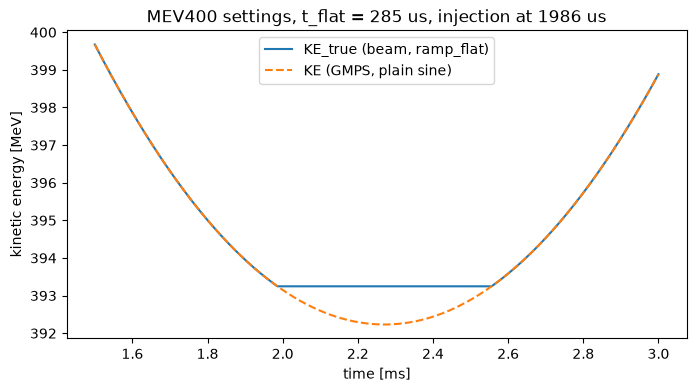

In [39]:
# KE_true vs KE (GMPS) around flat injection: the gap is what B:BFLAT supplies
t = np.linspace(1500, 3000, 600)
fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(t / 1000, rt.ke_at(settings, t) * 1000, label="KE_true (beam, ramp_flat)")
ax.plot(t / 1000, rt.ke_gmps_at(settings, t) * 1000, "--", label="KE (GMPS, plain sine)")
ax.set_xlabel("time [ms]")
ax.set_ylabel("kinetic energy [MeV]")
ax.set_title(f"MEV400 settings, t_flat = {settings['t_flat']:g} us, injection at {settings['t_offset'] - settings['t_flat']:g} us")
ax.legend()
plt.show()

### `B:BFLAT`
Group `B:BFLAT` = `B:BFLATT` (ramp table, `dtoff` 0 since 2026-10-14) + `B:BFLATS` (scale factor `sf`). Each has its own table number, so operators can remix them. `dd.value_at(bma, "B:BFLAT", t)` (= `madx_input.bflat_value`) is added to every `I_HS` and `I_HL`.

{'scale': 'B:BFLATS', 'table': 'B:BFLATT'}  sf = -3.0


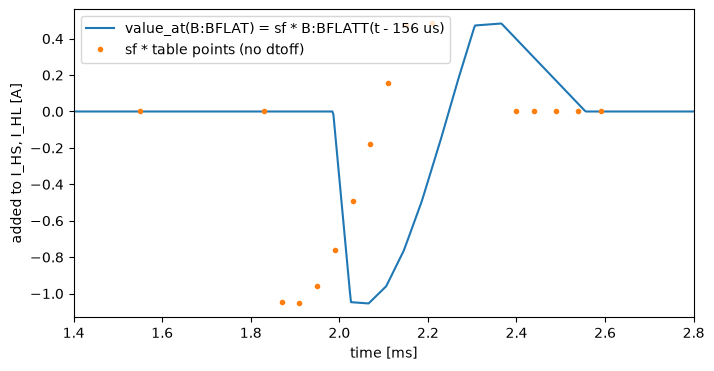

B:BFLAT at 2200 us: -0.3841552734375
I_HS1: -0.960693359375 -> -1.3448486328125
I_VS1: -6.029052734375 -> -6.029052734375 (unchanged)


In [40]:
from madx_input import bflat_value, bflat_sf
print(dd.groups(bma)["B:BFLAT"], " sf =", bflat_sf(bma))

t = np.linspace(1400, 2800, 600)
tb, vb = dd.ramp(bma["B:BFLATT"])
fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(t / 1000, dd.value_at(bma, "B:BFLAT", t), label=f"value_at(B:BFLAT) = sf * B:BFLATT(t - {bma['B:BFLATT']['dtoff']:g} us)")
ax.plot(tb / 1000, bflat_sf(bma) * vb, "o", ms=3, label="sf * table points (no dtoff)")
ax.set_xlim(1.4, 2.8)
ax.set_xlabel("time [ms]")
ax.set_ylabel("added to I_HS, I_HL [A]")
ax.legend()
plt.show()

no_bflat = {n: d for n, d in bma.items() if d.get("group") != "B:BFLAT"}
cur0 = common_values(2200.0, no_bflat, settings)          # inside flat injection (2007-2423 us)
cur1 = common_values(2200.0, bma, settings)
print("B:BFLAT at 2200 us:", bflat_value(bma, 2200.0))
print("I_HS1:", cur0["I_HS1"], "->", cur1["I_HS1"])
print("I_VS1:", cur0["I_VS1"], "->", cur1["I_VS1"], "(unchanged)")

### RF: three modes
The RF mode comes from which devices are in `devs` (`madx_input.rf_mode(devs)`; `rf="off"` forces the first):
- `"off"`: no RF phase devices → `V<nn>` = `LAG<nn>` = 0 (transverse only). RF voltages without phases raise an error.
- `"phase"`: phases, no voltages → `LAG<nn>` = phase / 360 from the phase devices (RFA or RFB), and one voltage on all cavities that are on, so the energy gain matches the ramp: V = dKE/turn [MV] / Σ_on sin(2π LAG<nn>), with dKE/turn = `rt.dke_at(settings, t)` (from `turn_energy`). With RF21/RF22 off: dKE/turn = 10 V sin φA + 10 V sin φB.
- `"phase+volt"`: phases and voltages → `LAG<nn>` from the phases, `V<nn>` = `B:RF<nn>GA(t - dtoff)` / 1000 (readbacks in kV, MAD-X in MV); the ramp is not used.

Which phase each cavity gets: the `RF_CAVITY_PHASE` device (cavity → `RFA` / `RFB`, in `rf_phase_curves.json`, section 3); without it there are no phases (mode `"off"`). Phases in degrees, LAG = phase / 360: MAD-X's reference particle gains V sin(2π LAG) at each cavity wherever it is (no arrival-time phase), so no 84 s / C term is added. Cavities in the map's `off` list (21, 22: no readback data) get V = 0 in both RF modes (`madx_input.off_cavities`). Below: the RF phase curves from section 3 with the BMA data.

In [41]:
from madx_input import rf_mode, rf_values, phase_names, off_cavities as mxin_off

vrf, _ = dd.load("data_Booster/10_23_26_VRF_READBACK_clean.json")
print("cavity phases:", phase_names({**bma, **phases}))
print("cavities off (V = 0):", sorted(mxin_off(phases)))

for name, pool in [("BMA only", bma), ("BMA + phases", {**bma, **phases}), ("BMA + phases + volts", {**bma, **phases, **vrf})]:
    mode = rf_mode(pool)
    volts, lags = rf_values(10000.0, pool, settings, mode)
    print(f"{name:22s} mode {mode:10s}  V01, V02, V21 = {volts[0]:.4f}, {volts[1]:.4f}, {volts[20]:.4f} MV  LAG01 (B) = {lags[0]:.4f}  LAG02 (A) = {lags[1]:.4f}")
print("dKE/turn at 10 ms:", rt.dke_at(settings, 10000.0) * 1e3, "MeV")
try:
    rf_mode({**bma, **vrf})
except ValueError as e:
    print("volts without phases:", e)

path = write_common(input_file, common_values(10000.0, {**bma, **phases}, settings))
print("\n".join(line for line in open(path).read().splitlines() if line.startswith(("!RF mode", "!LAG", "V01=", "V21=", "LAG01=", "LAG02="))))

cavity phases: ['RFB', 'RFA', 'RFA', 'RFB', 'RFB', 'RFA', 'RFA', 'RFB', 'RFA', 'RFB', 'RFB', 'RFA', 'RFA', 'RFB', 'RFB', 'RFA', 'RFA', 'RFB', 'RFB', 'RFA', 'RFB', 'RFA']
cavities off (V = 0): [21, 22]
BMA only               mode off         V01, V02, V21 = 0.0000, 0.0000, 0.0000 MV  LAG01 (B) = 0.0000  LAG02 (A) = 0.0000


BMA + phases           mode phase       V01, V02, V21 = 0.1909, 0.1909, 0.0000 MV  LAG01 (B) = 0.0220  LAG02 (A) = 0.0109
BMA + phases + volts   mode phase+volt  V01, V02, V21 = 0.0504, 0.0017, 0.0000 MV  LAG01 (B) = 0.0220  LAG02 (A) = 0.0109
dKE/turn at 10 ms: 0.39370367521941635 MeV
volts without phases: RF voltage devices given but no RF phase devices (remove the voltages for transverse only, or add the phases)
!RF mode phase: LAG<nn> from phase devices; V = dKE/turn [MV] / sum(sin(2 pi LAG)) over the on cavities
!LAG<nn> = 0.002777777777777778 * phase(t - dtoff) (RFA or RFB); V = 0 on cavities RF21, RF22
V01=0.19091411082454332;
V21=0.0;
LAG01=0.02200546111111111;
LAG02=0.01089407222222225;


## 6. `run_madx.py`: run a lattice at a setting (one point or a loop)

The steps:
1. **Config**: the lattice and a list of device files. All the files go into one pool of unique devices (a name in two files is an error). The pool must hold the ramp settings (`B:VIMIN`, ... from the lattice's `*_MISC_*.json`; `prepare` stops if its injection energy is more than 10% from the lattice's `KE_INJ`). Any current not in the pool is written as 0.
   - `overrides={name: value}`: constants that replace devices by name. A group (`"B:QL1"`) replaces the whole value S·T(t − dtoff) + O; a part (`"B:QL1O"`) replaces only that part, and the table keeps ramping. `B:HL3 = 0` leaves the `B:BFLAT` part of `I_HL3` on (override `"B:BFLAT"` for that). A name that matches nothing gets a warning and is ignored (`setup.ignored`).
   - `rm.batch_override(pool, value, kind="SQ")` gives `{group: value}` for every group of a kind; with `role="offset"` (or `"table"`) only those parts. Add it to the overrides (`pool = rm.load_devices(files)`). `B:BFLAT` is its own kind (`"BFLAT"`), so `kind="H"` leaves it alone.
2. `setup = rm.prepare(cfg)` loads everything once. The RF mode comes from the devices present (section 5). Painting is on if the lattice calls `PIP_II_Booster_injection.dat` (the PIP-II lattice).
3. `res = rm.run_point(setup, t)` at time `t` [µs] writes `Common_Booster_input.dat` (and for PIP-II `PIP_II_Booster_injection.dat`) and runs MAD-X **in place, in `madx_files/`**, like `./madx` there by hand. PIP-II is two-pass: pass 1 with all painting angles 0, the ORBUMP/painting angles from pass 1's sectormap (`painting.kick_angles`), then pass 2.
4. Every run overwrites the same files in `madx_files/` (inputs, `.outx` outputs, `madx.log`). Read what you need after each run: `res.twiss` (read right after the run), `res.inputs` (everything written to `Common_Booster_input.dat`: `res.inputs["I_QL1"]`, `res.inputs["V01"]`), `rm.output(setup, "sectormap_table")` / `"survey"` for the other tables, and `res.q1`, `res.chrom1`, `res.angles`, ...
5. `rm.scan(setup, times, collect=f)` loops and returns a DataFrame; `f(res)` returns a dict of anything extra to keep from each point.

Painting offsets [m] at `TREATYPOINT` (`Y_ORBUMP`, `Y_PM`, `X_PM`) are devices with those names (scalar or ramp) or overrides, else 0.

Command line, from the project root (prints one line per point; `--csv FILE` saves the table):
```
python helper_scripts/run_madx.py --lattice madx_files/MEV400_Booster_lattice.madx \
    --devices data_Booster/10_23_26_BMA.json data_Booster/10_23_26_MISC_MEV400.json \
    --batch H=0 V=0 --t 2400 5000
```
`--batch H=0 V=0.5` overrides every device of a kind to a value (BFLAT stays on; add `--override B:BFLAT=0`). Other options: `--override B:QL1=0 Y_PM=-0.016`, `--ke-source NAME`, `--rf off`, `--linspace START STOP N`, `--madx`, or a config JSON (`cfg.save(path)`) as the first argument.

In [42]:
import run_madx as rm

cfg = rm.Config(lattice="madx_files/PIP_II_Booster_lattice.madx",
                devices=["data_Booster/10_23_26_BMA.json", "data_Booster/10_23_26_MISC_PIP_II.json"],
                overrides={"Y_ORBUMP": -0.097, "Y_PM": -0.016, "X_PM": 0.0061})   # painting offsets [m]
setup = rm.prepare(cfg)
print(len(setup.devs), "devices, overrides", setup.overridden, "| RF mode", setup.rf_mode, "| painting", setup.painting, "| runs in", setup.folder)

res = rm.run_point(setup, 1900.0)
print(f"KE_true = {res.ke_true:.4f} GeV  Q1 = {res.q1:.4f}  Q2 = {res.q2:.4f}  xi1 = {res.chrom1:.2f}  xi2 = {res.chrom2:.2f}")
print({k: f"{v * 1e3:.4f} mrad" for k, v in res.angles.items()})

590 devices, overrides ['Y_ORBUMP', 'Y_PM', 'X_PM'] | RF mode off | painting True | runs in madx_files


KE_true = 0.7904 GeV  Q1 = 6.7614  Q2 = 6.8377  xi1 = -8.47  xi2 = -3.08
{'ORB_KICK_ANG': '-71.6951 mrad', 'VPML10_ANG': '-0.7964 mrad', 'VPML11U_ANG': '-0.1108 mrad', 'VPML11D_ANG': '-0.2410 mrad', 'VPML12_ANG': '-0.7910 mrad', 'HPMS09_ANG': '0.2647 mrad', 'HPMS10_ANG': '0.3636 mrad', 'HPMS11_ANG': '0.3502 mrad', 'HPMS12_ANG': '0.2712 mrad'}


Overrides: a whole group, one part of a group, a whole family (`batch_override`), and a typo (warned and ignored).

In [43]:
pool = rm.load_devices(["data_Booster/10_23_26_BMA.json", "data_Booster/10_23_26_MISC_MEV400.json"])
ocfg = rm.Config(lattice="madx_files/MEV400_Booster_lattice.madx",
                devices=["data_Booster/10_23_26_BMA.json", "data_Booster/10_23_26_MISC_MEV400.json"],
                overrides={"B:HL3": 0.0,       # group: I_HL3 = B:BFLAT only
                           "B:QL1O": 5.0,      # part: I_QL1 = S * QL1T(t - dtoff) + 5
                           "B:HL33": 1.0})     # typo: warning, ignored
ocfg.overrides.update(rm.batch_override(pool, 0.0, kind="SQ"))                # all 48 skew quads at 0 A
ocfg.overrides.update(rm.batch_override(pool, 0.0, kind="SX", role="offset"))  # only the sextupole offsets
osetup = rm.prepare(ocfg)
ores = rm.run_point(osetup, 2200.0)                       # inside flat injection, BFLAT on
print(len(osetup.overridden), "applied, ignored:", osetup.ignored)
print({k: round(ores.inputs[k], 4) for k in ("I_HL3", "I_QL1", "I_SXL1", "I_SQL1")}, "| B:BFLAT =", round(ores.inputs.bflat, 4))


/mnt/c/Users/mabal/Documents/ai_working/Booster_lattice_release/helper_scripts/run_madx.py:247: UserWarning: override 'B:HL33' matches no device in the pool and no MAD-X input; ignored (typo?)
  devs, applied, ignored = apply_overrides(load_devices(cfg.devices), cfg.overrides)


98 applied, ignored: ['B:HL33']
{'I_HL3': -0.3842, 'I_QL1': 2.9567, 'I_SXL1': 8.7487, 'I_SQL1': 0.0} | B:BFLAT = -0.3842


bump at TREATYPOINT: dx = 6.133 mm, dy = -113.250 mm
offsets: X_PM = 6.100 mm, Y_ORBUMP + Y_PM = -113.000 mm


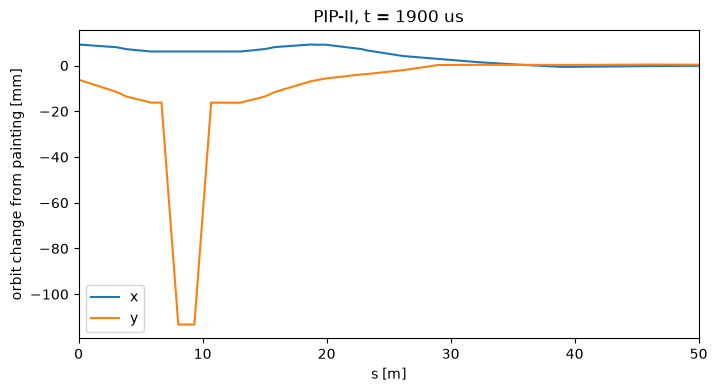

In [44]:
# The painting bump: the same point with the painting offsets at 0, minus with them
no_paint = rm.prepare(rm.Config(lattice=cfg.lattice, devices=cfg.devices,
                                overrides={"Y_ORBUMP": 0.0, "Y_PM": 0.0, "X_PM": 0.0}))
tw0 = rm.run_point(no_paint, 1900.0).twiss
tw1 = rm.run_point(setup, 1900.0).twiss          # setup from the cell above (with painting)
i = tw1.idx("TREATYPOINT")
print("bump at TREATYPOINT: dx = %.3f mm, dy = %.3f mm" % ((tw1["X"][i] - tw0["X"][i]) * 1e3, (tw1["Y"][i] - tw0["Y"][i]) * 1e3))
print("offsets: X_PM = %.3f mm, Y_ORBUMP + Y_PM = %.3f mm" % (cfg.overrides["X_PM"] * 1e3, (cfg.overrides["Y_ORBUMP"] + cfg.overrides["Y_PM"]) * 1e3))

fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(tw1["S"], (tw1["X"] - tw0["X"]) * 1e3, label="x")
ax.plot(tw1["S"], (tw1["Y"] - tw0["Y"]) * 1e3, label="y")
ax.set_xlim(0, 50)
ax.set_xlabel("s [m]")
ax.set_ylabel("orbit change from painting [mm]")
ax.set_title("PIP-II, t = 1900 us")
ax.legend()
plt.show()


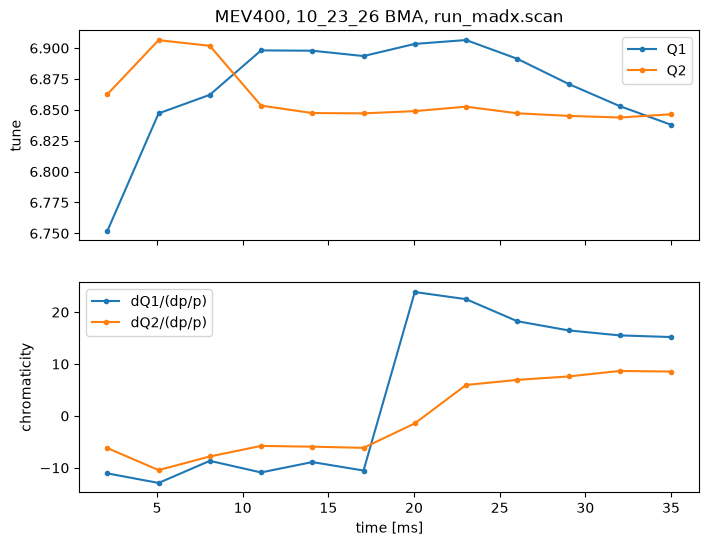

,t,ke_true,ke,q1,q2,chrom1,chrom2,betx_bpm_l11,I_QL1
0,2100.000000,0.393247,0.392597,6.751931,6.862583,-11.068247,-6.196427,8.501648,2.827583
1,5090.909091,0.494346,0.494346,6.847118,6.906449,-12.913287,-10.438604,8.163806,1.023935
2,8081.818182,0.850963,0.850963,6.862165,6.901848,-8.653004,-7.808741,6.775319,-0.384433
3,11072.727273,1.482631,1.482631,6.898133,6.853420,-10.889281,-5.778711,7.777323,-1.672754
4,14063.636364,2.349748,2.349748,6.897882,6.847411,-8.892209,-5.927069,7.296206,-3.111706


In [45]:
# Loop (MEV400, no painting: one MAD-X run per point, ~1.5 s), keeping beta x at one element as well
cfg = rm.Config(lattice="madx_files/MEV400_Booster_lattice.madx",
                devices=["data_Booster/10_23_26_BMA.json", "data_Booster/10_23_26_MISC_MEV400.json"])
setup = rm.prepare(cfg)
df = rm.scan(setup, np.linspace(2100, 35000, 12), verbose=False,   # from just after injection (2007 us)
             collect=lambda res: {"betx_bpm_l11": res.twiss.row("BMAL11_BPM")["BETX"], "I_QL1": res.inputs["I_QL1"]})

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(8, 6), sharex=True)
ax1.plot(df.t / 1000, df.q1, ".-", label="Q1")
ax1.plot(df.t / 1000, df.q2, ".-", label="Q2")
ax1.set_ylabel("tune")
ax1.legend()
ax2.plot(df.t / 1000, df.chrom1, ".-", label="dQ1/(dp/p)")
ax2.plot(df.t / 1000, df.chrom2, ".-", label="dQ2/(dp/p)")
ax2.set_ylabel("chromaticity")
ax2.set_xlabel("time [ms]")
ax2.legend()
ax1.set_title("MEV400, 10_23_26 BMA, run_madx.scan")
plt.show()
df[["t", "ke_true", "ke", "q1", "q2", "chrom1", "chrom2", "betx_bpm_l11", "I_QL1"]].head()

### With and without RF over the ramp
Two setups with the same devices, one with RF (`rf_phase_curves.json` in the pool) and one with `rf="off"`, scanned over the same times. Away from transition RF changes the tunes by < 0.001. Near transition (η → 0) the RF-on closed orbit goes off momentum by about −(ΔC/C)/η, where ΔC is the closed-orbit length change from the H/V correctors, so the tunes jump and some points fail (`nan`, marked ×). The machine's radial position loop would hold the beam on momentum; that is not modelled yet.

phase vs off | 5 of 23 RF-on points failed


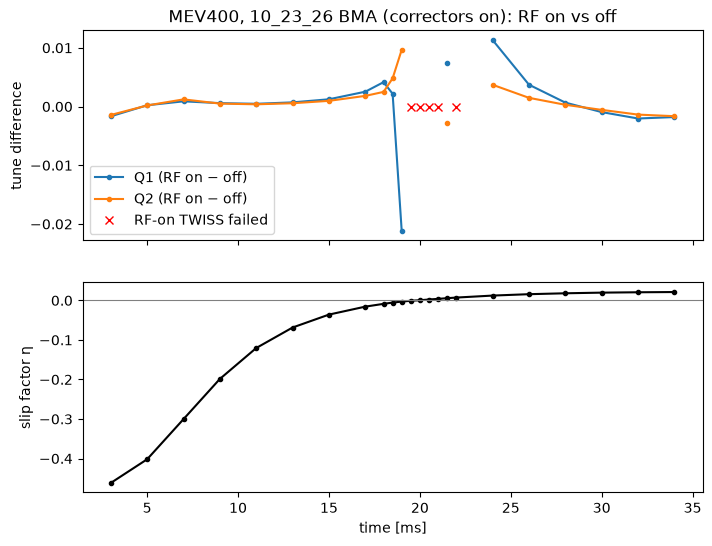

In [46]:
devices = ["data_Booster/10_23_26_BMA.json", "data_Booster/10_23_26_MISC_MEV400.json", "data_Booster/rf_phase_curves.json"]
lattice = "madx_files/MEV400_Booster_lattice.madx"
with_rf = rm.prepare(rm.Config(lattice=lattice, devices=devices))
no_rf = rm.prepare(rm.Config(lattice=lattice, devices=devices, rf="off"))
times = np.r_[np.arange(3000, 17001, 2000), np.arange(18000, 22001, 500), np.arange(24000, 34001, 2000)]
eta = lambda res: {"eta": 1 / res.twiss.header["GAMMATR"] ** 2 - 1 / res.twiss.header["GAMMA"] ** 2}
on = rm.scan(with_rf, times, verbose=False)
off = rm.scan(no_rf, times, verbose=False, collect=eta)
print(with_rf.rf_mode, "vs", no_rf.rf_mode, "|", int(on.q1.isna().sum()), "of", len(times), "RF-on points failed")

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(8, 6), sharex=True)
ax1.plot(off.t / 1000, on.q1 - off.q1, ".-", label="Q1 (RF on − off)")
ax1.plot(off.t / 1000, on.q2 - off.q2, ".-", label="Q2 (RF on − off)")
bad = on.q1.isna()
ax1.plot(off.t[bad] / 1000, np.zeros(bad.sum()), "rx", label="RF-on TWISS failed")
ax1.set_ylabel("tune difference")
ax1.legend()
ax2.plot(off.t / 1000, off.eta, ".-", color="k")
ax2.axhline(0, color="gray", lw=0.8)
ax2.set_ylabel("slip factor η")
ax2.set_xlabel("time [ms]")
ax1.set_title("MEV400, 10_23_26 BMA (correctors on): RF on vs off")
plt.show()

## 7. `bpm_data.py`: BPM turn-by-turn data and turn timing

BPM data as devices, one per BPM and plane (`B:HST<nn><L|S>` = x, `B:VST<nn><L|S>` = y, BPM sign):
- `values`: numpy array, one reading per turn [mm], NaN = no reading (1000 in the files).
- `begin_turn`: turn number of `values[0]` as recorded; `turn_offset`: correction if the BPM is some turns off (e.g. −1 for L24/S24 in the 10-20 data). Turn of `values[m]` = `begin_turn + turn_offset + m`.
- `timing`: the name of the turn-timing device in the same dict, `bd.TIMING` = `"TBT_TIME"`.

The timing device has `values` = turn numbers 0, 1, 2, ..., `t` = the cycle time of each turn [µs] and `ke` [GeV], from `rt.turn_energy` started at turn 0 = `bd.TURN0` = 2000 µs. It is a table, so `dd.value_at(devs, "TBT_TIME", t)` is the turn number at time `t`.
- Data files: `data_Booster/10_20_26_BPM_TBT_{noping,hping,vping}.json` (cycle 17, 2026-10-20; L24/S24 `turn_offset` −1), the format the pacsys data will be saved in. `bd.load(path)` reads one.
- `bd.read_tbt(path)` reads the user's turn-by-turn text files, `bd.add_timing(devs, settings)` adds the timing device (again after a timing change), `bd.read(path)` takes a text file or a `.json`. The files above were made with `python helper_scripts/bpm_data.py TBT.txt --misc data_Booster/10_23_26_MISC_MEV400.json --out OUT.json --turn-offset B:HST24L=-1 ...`.
- `bd.turns(dev)`, `bd.times(dev, devs)`, `bd.turn_at(timing, t)`, `bd.index_at(dev, devs, t)`, `bd.set_turn_offsets(devs, {...})`.
- `bd.save(devs, path, meta)` / `bd.load(path)`: the device_data JSON format, one device per line (about the size of the text file).
- `bd.planes(devs)`: the 48 BPMs of each plane as (48, n_turns) arrays, turn offsets applied.

The BPMs are in an injection mode for the first 10-20 turns (different gain and frequency structure) before switching to the normal mode; expect turns before 100 to behave a bit differently (kept; `read_tbt(first_turn=bd.GAIN_TURNS)` drops them).

In [47]:
import bpm_data as bd

tbt, meta = bd.load("data_Booster/10_20_26_BPM_TBT_noping.json")      # no ping
print(meta["notes"])
dev = tbt["B:HST05L"]
print({k: v for k, v in dev.items() if k != "values"})
T = tbt[bd.TIMING]
print(f"timing ({T['source']}): {len(T['t'])} turns, turn 0 at {T['t'][0]:g} us, last at {T['t'][-1]:.0f} us ({T['ke'][-1]:.3f} GeV)")
i = bd.index_at(dev, tbt, 8000.0)
print(f"turn at 8 ms: {bd.turn_at(T, 8000.0):.2f} -> values[{i}] (turn {bd.turns(dev)[i]}, t = {bd.times(dev, tbt)[i]:.1f} us) = {dev['values'][i]} mm")
print("same turn from dd.value_at:", dd.value_at(tbt, bd.TIMING, 8000.0))
print("turn offsets:", {n: d["turn_offset"] for n, d in bd.bpm_devices(tbt).items() if d["turn_offset"]})

2026-10-25: from TBT_modelnpingtbtBPM.txt (bpm_data.read_tbt); timing device from 10_23_26_MISC_MEV400.json (turn 0 at 2000 us); turn offsets {'B:HST24L': -1, 'B:VST24L': -1, 'B:HST24S': -1, 'B:VST24S': -1}. Cycle 17, 2026-10-20. L24/S24 one turn off (ping_analysis.fit_turn_offsets, 2026-10-24). noping: no ping. Timing rebuilt with KEMAX 7.988 (2026-10-25).
{'kind': 'BPM', 'role': 'tbt', 'plane': 'x', 'unit': 'mm', 'begin_turn': 1, 'turn_offset': 0, 'timing': 'TBT_TIME', 'cycle': 17, 'timestamp': '10/20/26 15:22:42', 'source': 'TBT_modelnpingtbtBPM.txt', 'group': 'B:HST05L'}
timing (10_23_26_MISC_MEV400.json): 19942 turns, turn 0 at 2000 us, last at 35763 us (7.988 GeV)
turn at 8 ms: 2890.14 -> values[2889] (turn 2890, t = 7999.7 us) = 0.3165 mm
same turn from dd.value_at: 2890.1363392377884
turn offsets: {'B:HST24L': -1, 'B:HST24S': -1, 'B:VST24L': -1, 'B:VST24S': -1}


In [48]:
# save and read back (the same JSON format)
import tempfile, pathlib
path = pathlib.Path(tempfile.gettempdir()) / "bpm_example.json"
bd.save(tbt, path, {"notes": "example"})
back = bd.load(path)[0]
print(f"{path.stat().st_size / 1e6:.1f} MB; values equal:",
      all(np.array_equal(tbt[n]["values"], back[n]["values"], equal_nan=True) for n in bd.bpm_devices(tbt)))
print(open(path).read(400))
arr = bd.planes(tbt)
print("planes:", arr["x"].shape, "begin_turn", arr["begin_turn"])

14.1 MB; values equal: True
{"meta": {"notes": "example", "created": "2026-10-25T20:56:02", "modified": "2026-10-25T20:56:02"},
 "devices": {
  "TBT_TIME": {"kind": "TBT_TIMING", "role": "table", "group": "TBT_TIME", "unit": "turn", "t0": 2000.0, "source": "10_23_26_MISC_MEV400.json", "values": [0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20,21,22,23,24,25,26,27,28,29,30,31,32,33,34,35,36,37,38,39,40,41,42,43,44,45,46,
planes: (48, 20000) begin_turn 1


## 8. `bpm_compare.py`: model orbit vs measured BPMs

Compares the model closed orbit at the 48 BMA BPMs (`BMAL<n>_BPM`, `BMAS<n>_BPM`) at a time `t` with measured turn-by-turn BPM data at the same time.
- `bc.model_orbit(twiss)`: X, Y [mm] at the BPMs from a run's twiss table, with s, beta and dispersion.
- Measured data: the `bpm_data` devices (section 7), named by `bd.ACNET_NAME` (`B:HST05L` = x at `BMAL5_BPM`, `B:VST12S` = y at `BMAS12_BPM`; or pass `names=`); the reading times come from their timing device.
- `bc.slow_orbit(dev, t, window, order, t_dev)`: a straight-line fit (default) to the points within `t ± window/2` follows the slow ramp; the betatron oscillation and noise average out. Gives the value at `t`, its error, the slope and the residual rms.
- `bc.measured_orbit(devs, t)` does that for every BPM, `bc.compare(model, measured)` lines them up (model − measured), `bc.plot_compare` plots both along the ring.

First a synthetic "measurement" (the model orbit at 7.8, 8.0 and 8.2 ms interpolated turn by turn, plus a decaying 2 mm betatron oscillation and 0.5 mm noise) to check the method, then the measured data of 2026-10-20 (no ping). A comparison at 14 times along the ramp is available from the author.

In [49]:
import bpm_compare as bc

setup = rm.prepare(rm.Config(lattice="madx_files/MEV400_Booster_lattice.madx",
                             devices=["data_Booster/10_23_26_BMA.json", "data_Booster/10_23_26_MISC_MEV400.json"]))
ts = [7800.0, 8000.0, 8200.0]
models = {t: bc.model_orbit(rm.run_point(setup, t).twiss) for t in ts}
models[8000.0].head()

,name,s,x,y,betx,bety,dx,mux,muy
0,BMAL11_BPM,11.993805,7.511081,-22.320898,6.774986,20.497168,1.147720,0.176816,0.137902
1,BMAS11_BPM,19.450494,27.493550,-28.523203,29.571408,4.586810,2.412669,0.262862,0.275346
2,BMAL12_BPM,31.750893,-1.689493,-50.440181,6.957505,21.479946,3.208068,0.481532,0.439740
3,BMAS12_BPM,38.842418,-12.274800,-9.197781,39.435238,4.947436,6.666731,0.551598,0.554586
4,BMAL13_BPM,51.497096,-21.664434,50.030462,6.658672,20.535201,2.588230,0.752622,0.737052


In [50]:
# synthetic turn-by-turn data around 8 ms, one device per BPM and plane, with its own timing device
timing = bd.timing_device(setup.settings)
w = (timing["t"] > 7700) & (timing["t"] < 8300)
t_turn, turns = timing["t"][w], timing["values"][w].astype(int)
rng = np.random.default_rng(1)
bpm_devs = {bd.TIMING: timing}
for el, _, _ in bd.bpm_elements():
    for plane, q in (("x", 0.84), ("y", 0.92)):
        slow = bc.BPM_SIGN[plane] * np.interp(t_turn, ts, [models[t].set_index("name").loc[el, plane] for t in ts])   # BPM sign
        osc = 2.0 * np.exp(-(t_turn - 7700) / 300) * np.cos(2 * np.pi * q * turns + rng.uniform(0, 2 * np.pi))
        bpm_devs[bd.acnet_name(el, plane)] = bd.bpm_device(slow + osc + rng.normal(0, 0.5, len(t_turn)), plane,
                                                           begin_turn=turns[0])
print(len(bpm_devs) - 1, "BPM devices, e.g.", list(bpm_devs)[1:5])
d = bpm_devs["B:HST05L"]
print(bc.slow_orbit(d, 8000.0, window=200.0, t_dev=bd.times(d, bpm_devs)))

96 BPM devices, e.g. ['B:HST01L', 'B:VST01L', 'B:HST01S', 'B:VST01S']
{'value': -3.3692082231635623, 'err': 0.07345564439655111, 'slope': 0.03793914160976581, 'noise': 0.752685224556389, 'n': 107}


rms(model - measured) [mm]: {'x': 0.051, 'y': 0.048}


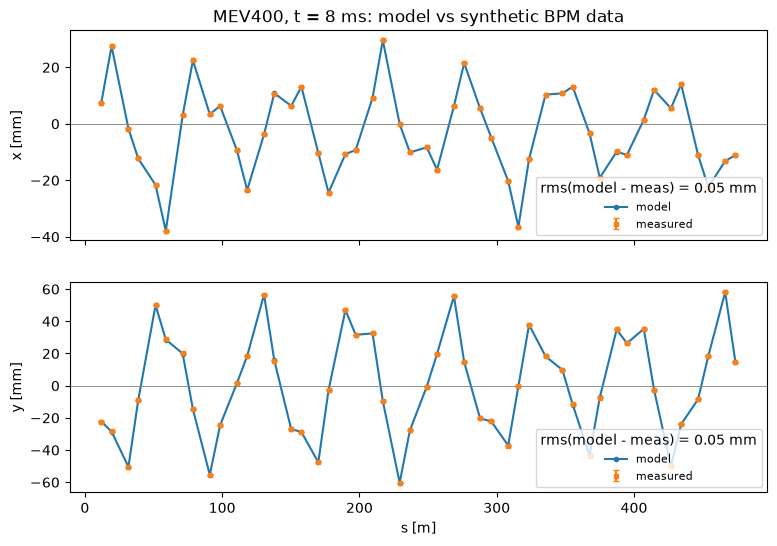

,name,s,x_model,x_meas,x_err,dx_mm,y_model,y_meas,y_err,dy_mm
0,BMAL11_BPM,11.993805,7.511081,7.503894,0.075345,0.007187,-22.320898,-22.322289,0.072033,0.001392
1,BMAS11_BPM,19.450494,27.493550,27.419413,0.070005,0.074137,-28.523203,-28.467157,0.070142,-0.056046
2,BMAL12_BPM,31.750893,-1.689493,-1.696944,0.073500,0.007451,-50.440181,-50.497999,0.076229,0.057818
3,BMAS12_BPM,38.842418,-12.274800,-12.202313,0.067033,-0.072487,-9.197781,-9.137092,0.074891,-0.060689
4,BMAL13_BPM,51.497096,-21.664434,-21.652167,0.067577,-0.012266,50.030462,49.925045,0.071072,0.105417


In [51]:
meas = bc.measured_orbit(bpm_devs, 8000.0, window=200.0)
cmp = bc.compare(models[8000.0], meas)
print("rms(model - measured) [mm]:", {k: round(v, 3) for k, v in cmp.attrs["rms"].items()})
bc.plot_compare(cmp, title="MEV400, t = 8 ms: model vs synthetic BPM data")
plt.show()
cmp[["name", "s", "x_model", "x_meas", "x_err", "dx_mm", "y_model", "y_meas", "y_err", "dy_mm"]].head()

Measured data (cycle 17, 2026-10-20, no ping), read in section 7 (`tbt`):

{'value': 0.3314161191343798, 'err': 0.002284073846623479, 'slope': 0.43341929394350565, 'noise': 0.02340444560956404, 'n': 107}
rms(model - measured) [mm]: {'x': 15.08, 'y': 32.07}


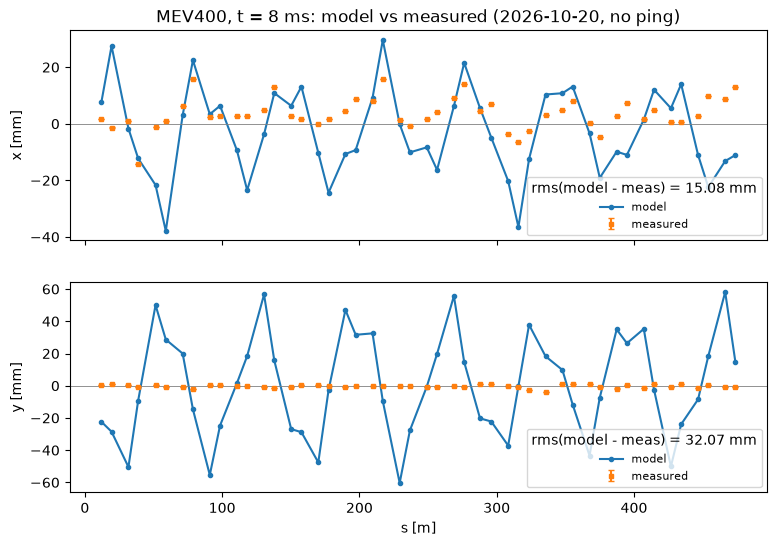

In [52]:
print(bc.slow_orbit(dev, 8000.0, window=200.0, t_dev=bd.times(dev, tbt)))
cmp_meas = bc.compare(models[8000.0], bc.measured_orbit(tbt, 8000.0, window=200.0))
print("rms(model - measured) [mm]:", {k: round(v, 2) for k, v in cmp_meas.attrs["rms"].items()})
bc.plot_compare(cmp_meas, title="MEV400, t = 8 ms: model vs measured (2026-10-20, no ping)")
plt.show()

## 9. `ping_analysis.py`: tunes, coupling, phase advances and betas from pings

The user's method: pings found at their regular spacing, the whole window up to the next ping, missing points interpolated, second difference `v[n] - (v[n-1] + v[n+1])/2` (removes the closed orbit), plain FFT, 3-point parabola on the peak, `Q = 7 - q`.
- `pa.planes(devs)` (= `bd.planes`, turn offsets applied): the 48 BMA BPMs of each plane as arrays (text file or saved `.json`).
- `pa.tune_table(data, timing, noping=...)` (`timing`: the turn-timing device): one row per ping: the two eigenmodes A (horizontal-like) and B (vertical-like), labelled by their H/V amplitude ratio (with strong coupling the largest peak in the pinged plane isn't always the pinged mode), coupling ratios, half-window spread, SNR.
- `pa.optics_table(data, tunes, model)`: per ping and BPM, the phase (Fourier coefficient at the mode's q), the advance to the next BPM, and betas from the amplitude and from the phase (three BPMs). With a model it also fits integer turn offsets per BPM: in the 10-20 data, L24 and S24 are one turn off from the others (now set as `turn_offset` in the data files, so the fit finds none). `offsets.phase_offset_turns` shows what's left (L12-S14: about 0.6, not understood).
- Command line: `python helper_scripts/ping_analysis.py --h H.txt|.json --v V.txt|.json --n N.txt|.json --misc MISC.json (not needed for .json files with a timing device) --lattice L --devices F.. --out DIR`.


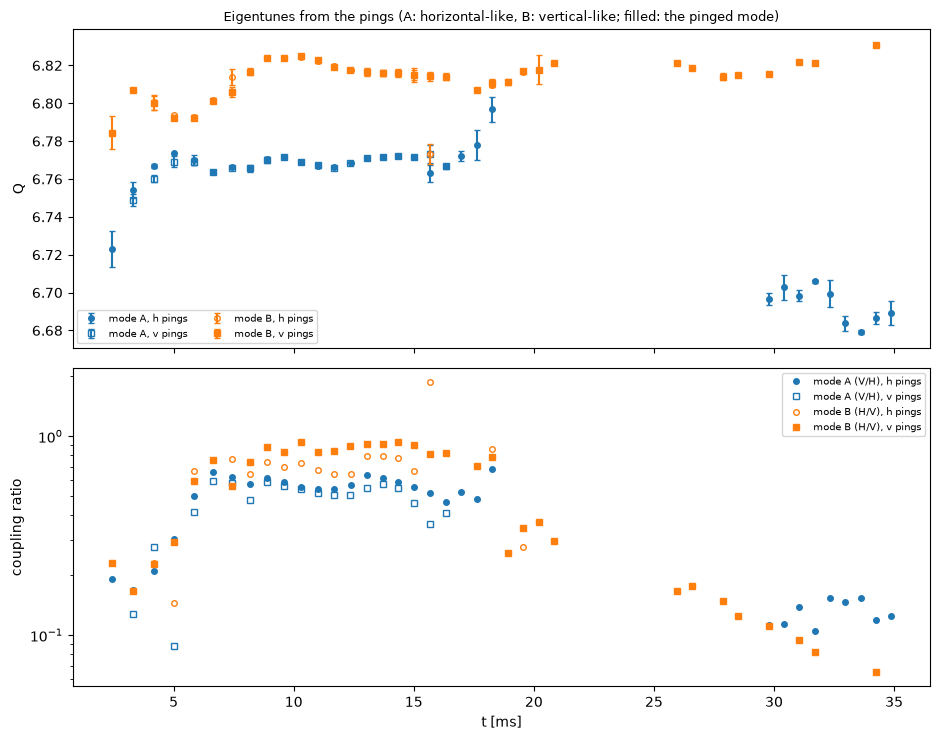

,ping,t_ms,n_turns,Q_A,Q_B,coupling_A,coupling_B,snr_A,snr_B
0,h,2.421332,398,6.723085,6.732473,0.190609,4.861678,3.026922,0.755104
1,h,3.305822,399,6.754211,6.807185,0.167911,0.371081,17.863906,2.176376
2,h,4.178557,401,6.767051,6.800446,0.208914,0.231396,22.803692,4.226094
3,h,5.032937,399,6.773495,6.793889,0.304233,0.144933,35.621334,8.980969
4,h,5.856298,394,6.770218,6.792944,0.497959,0.668211,25.754713,10.645194


In [53]:
import ping_analysis as pa

data = {k: pa.planes(bd.load(f"data_Booster/10_20_26_BPM_TBT_{k}ping.json")[0]) for k in ("h", "v")}
noping = pa.planes(tbt)
tunes = pa.tune_table(data, tbt[bd.TIMING], noping=noping)
pa.plot_tunes(tunes)
plt.show()
tunes[["ping", "t_ms", "n_turns", "Q_A", "Q_B", "coupling_A", "coupling_B", "snr_A", "snr_B"]].head()

turn offsets: {}


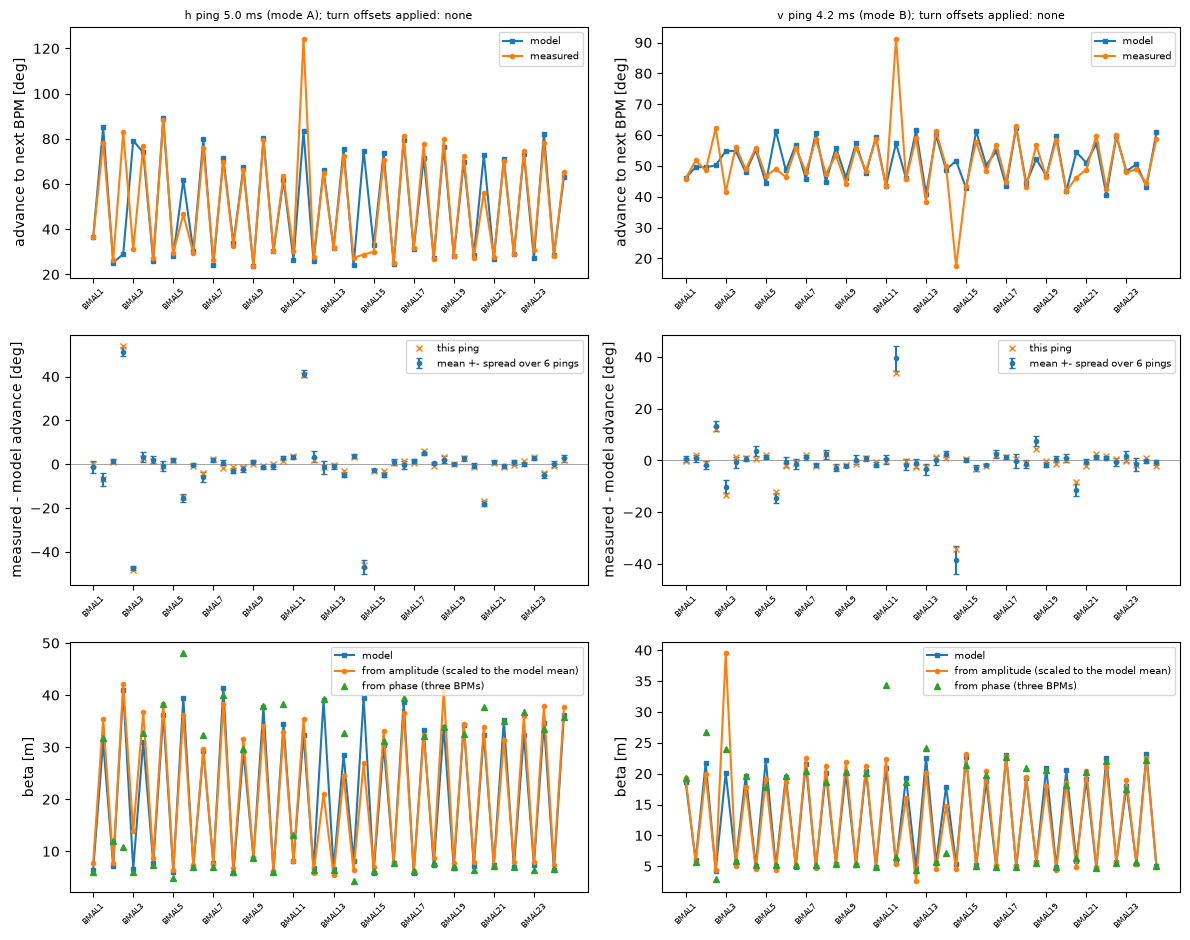

In [54]:
# model optics (H = V = 0, RF off) at each ping time, here only the pings at 3-8 ms (one MAD-X run each)
cfg = rm.Config(lattice="madx_files/MEV400_Booster_lattice.madx",
                devices=["data_Booster/10_23_26_BMA.json", "data_Booster/10_23_26_MISC_MEV400.json"], rf="off")
pool = rm.load_devices(cfg.devices)
cfg.overrides = {**rm.batch_override(pool, 0.0, kind="H"), **rm.batch_override(pool, 0.0, kind="V")}
bare = rm.prepare(cfg)
model = lambda t_ms: pa.model_optics(rm.run_point(bare, 1000.0 * t_ms).twiss)
optics, offsets = pa.optics_table(data, tunes[(tunes.t_ms > 3) & (tunes.t_ms < 8)], model)
print("turn offsets:", {b: m for b, m in zip(offsets.bpm, offsets.turn_offset) if m})
pa.plot_optics(optics, {"h": 5.0, "v": 4.2})
plt.show()

## 10. `timing_fit.py`: GMPS and RF timing from B:BFLAT and the RF curve

The user's method (2026-10-25):
1. Only the BMA magnets (correctors, B:BFLAT) have the 156 µs delay (their `dtoff`), taken as a pure delay.
2. B:BFLAT's nontrivial part (from the last zero point before it to the first zero point after it, + `dtoff`) is the flat injection region: `BDOT` = its centre (GMPS minimum), `TFLAT` = half its length. PIP-II keeps its own `TFLAT` (and 20 Hz) with the same `BDOT`.
3. The ramp from `B:VIMIN` (trough), `B:VIMAX` (peak) and `KEMAX` (`rt.ramp_settings`); injection KE = the sine at `BDOT + TFLAT`.
4. The RF curves start at the programmed 1875 µs (`t_start`); their `dtoff` is the extra delay on top. `tf.fit_rf_offset` fits it: `pc_curve(t - dtoff) = scale * pc_ramp(t)`, the pc scale free so a `KEMAX` error doesn't pull the time (`ke_max_rf` = the top the RF curve implies). The phase curves get the same `dtoff`. Transition vs the phase jump is only reported.

The command line does the same and `--apply` writes `BDOT`/`TFLAT` and the RF `dtoff` into the files (README, "Relative timing").

B:BFLAT window [us]: (1986.0, 2556.0)
{'BDOT': 2271.0, 'TFLAT': 285.0}   (file: 2271.0 285.0 )
trough 0.39223 GeV, flat injection 0.39325 GeV
RF extra dtoff 155.2 us (file 155.2), scale 1.00004 -> top 7.9884 GeV, rms 4.5 MeV
phase jump 19.465 ms, ramp at gamma_t 5.592: 19.613 ms


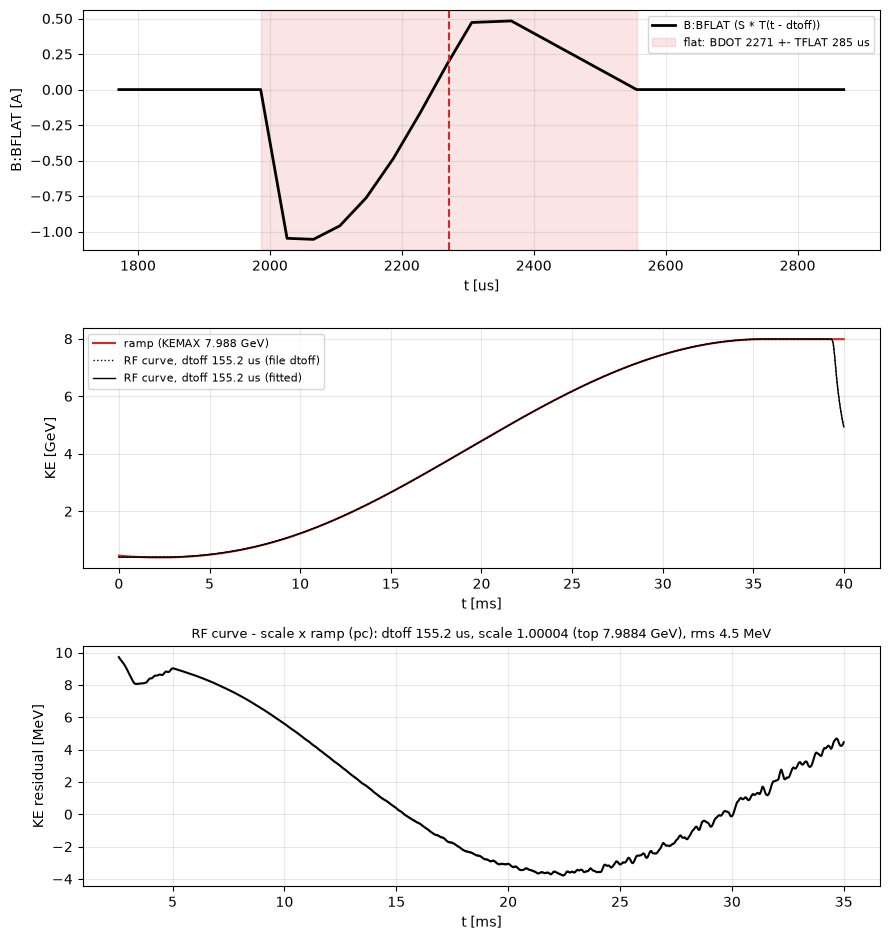

In [55]:
import timing_fit as tf

bma = dd.load("data_Booster/10_23_26_BMA.json")[0]
misc = dd.load("data_Booster/10_23_26_MISC_MEV400.json")[0]
freq = dd.load("data_Booster/rf_freq_20260914.json")[0]["tblFreqCurveFF"]
phases = dd.load("data_Booster/rf_phase_curves.json")[0]

print("B:BFLAT window [us]:", tf.bflat_window(bma))
flat = tf.flat_from_bflat(bma)
print(flat, "  (file:", misc["BDOT"]["value"], misc["TFLAT"]["value"], ")")
s = tf.settings_with(misc, flat)
print(f"trough {s['vimin']:.5f} GeV, flat injection {s['viflat']:.5f} GeV")

fit = tf.fit_rf_offset(s, freq)
print(f"RF extra dtoff {fit['dtoff']:.1f} us (file {freq['dtoff']}), scale {fit['scale']:.5f} -> top {fit['ke_max_rf']:.4f} GeV, "
      f"rms {1e3 * fit['rms']:.1f} MeV")
print(f"phase jump {tf.phase_jump_time(phases['RFA'], fit['dtoff']) / 1e3:.3f} ms, "
      f"ramp at gamma_t 5.592: {tf.transition_time(s, 5.592) / 1e3:.3f} ms")
tf.plot_timing(bma, s, freq, fit)
plt.show()

## 11. `pip2_ramps.py`: PIP-II sample ramps from the MEV400 ramps

The PIP-II ramp (20 Hz, injection 0.79 GeV) is a compressed MEV400 ramp with the same `BDOT` and `KEMAX`. Each table breakpoint goes to the PIP-II time with the same Brho and keeps its value (same current at the same Brho = same kick or strength); delays (`dtoff`) stay on the magnet side.
- MEV400 breakpoints before it reaches the PIP-II injection energy (~7.7 ms) are dropped. Through PIP-II flat injection the BMA tables give the same strength as MEV400 at 2000 µs (current × the Brho ratio, `p2.injection_value`), then interpolate to the first Brho-matched breakpoint. RF phases hold their 7.7 ms value.
- Past the MEV400 top: shifted by the difference of the top times. Tables keep at most their 64 slots, breakpoints 1:1.
- B:BFLAT: stretched in time about BDOT (TFLAT 285 → 400 µs) and its current scaled by the Brho ratio of the flat levels.
- RF phase curves: mapped by beam Brho, so the transition phase jump lands at PIP-II transition.

Files: `data_Booster/10_23_26_BMA_PIP_II.json`, `data_Booster/rf_phase_curves_PIP_II.json`, made with `python helper_scripts/pip2_ramps.py --bma data_Booster/10_23_26_BMA.json --misc400 data_Booster/10_23_26_MISC_MEV400.json --misc-pip data_Booster/10_23_26_MISC_PIP_II.json --out-bma data_Booster/10_23_26_BMA_PIP_II.json --phases data_Booster/rf_phase_curves.json --out-phases data_Booster/rf_phase_curves_PIP_II.json`.

MEV400 reaches the PIP-II injection KE 0.7904 GeV at 7703 us
same KE: [1.0163 2.6578 6.1791] [1.0163 2.6578 6.1791] at PIP-II t = [ 5309. 11011. 19026.]
B:QL1 MEV400 [ -0.923  -3.72  -12.695]  PIP-II [ -0.926  -3.721 -12.695]
PIP-II phase jump 14.654 ms, ramp at gamma_t 5.534: 14.653 ms


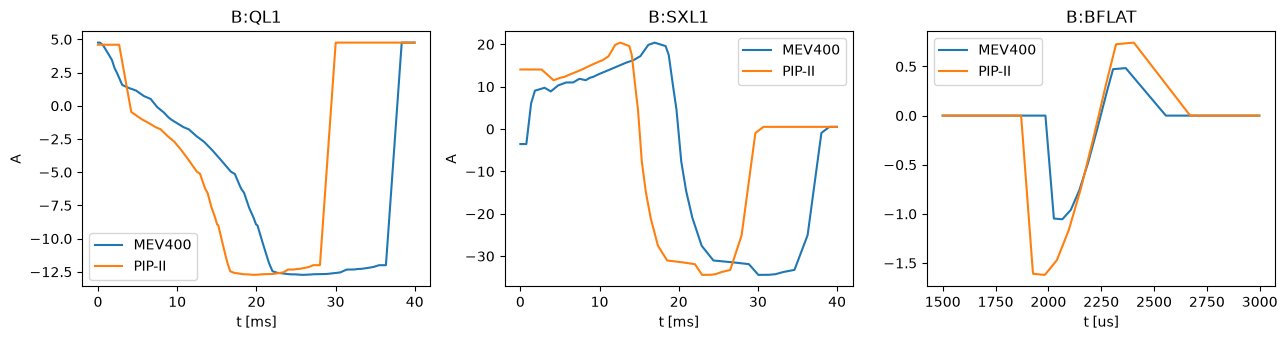

In [56]:
import pip2_ramps as p2
import timing_fit as tf

s400 = rt.ramp_settings(dd.load("data_Booster/10_23_26_MISC_MEV400.json")[0])
spip = rt.ramp_settings(dd.load("data_Booster/10_23_26_MISC_PIP_II.json")[0])
bma = dd.load("data_Booster/10_23_26_BMA.json")[0]
bma_pip = dd.load("data_Booster/10_23_26_BMA_PIP_II.json")[0]
print(f"MEV400 reaches the PIP-II injection KE {spip['viflat']:.4f} GeV at {p2.t_inj(s400, spip):.0f} us")
t4 = np.array([9000.0, 15000.0, 25000.0])
tp = p2.map_time(t4, s400, spip)
print("same KE:", rt.ke_at(s400, t4).round(4), rt.ke_at(spip, tp).round(4), "at PIP-II t =", tp.round(0))
print("B:QL1 MEV400", dd.value_at(bma, "B:QL1", t4).round(3), " PIP-II", dd.value_at(bma_pip, "B:QL1", tp).round(3))
ph_pip = dd.load("data_Booster/rf_phase_curves_PIP_II.json")[0]
print(f"PIP-II phase jump {tf.phase_jump_time(ph_pip['RFA']) / 1e3:.3f} ms, ramp at gamma_t 5.534: {tf.transition_time(spip, 5.534) / 1e3:.3f} ms")

fig, ax = plt.subplots(1, 3, figsize=(13, 3.5))
for a, name in zip(ax[:2], ("B:QL1", "B:SXL1")):
    t = np.arange(0, 40000, 20.0)
    a.plot(t / 1e3, dd.value_at(bma, name, t), label="MEV400")
    a.plot(t / 1e3, dd.value_at(bma_pip, name, t), label="PIP-II")
    a.set_title(name); a.set_xlabel("t [ms]"); a.set_ylabel("A"); a.legend()
t = np.arange(1500, 3000, 2.0)
ax[2].plot(t, dd.value_at(bma, "B:BFLAT", t), label="MEV400")
ax[2].plot(t, dd.value_at(bma_pip, "B:BFLAT", t), label="PIP-II")
ax[2].set_title("B:BFLAT"); ax[2].set_xlabel("t [us]"); ax[2].legend()
fig.tight_layout(); plt.show()